# 01 — Data Understanding

**Dataset:** CMI time series (DM2 2025/26) — 4437 finestre da 200 timestep di dati accelerometrici da polso, target `sii_binary` (0 = non problematico, 1 = problematico).

**Cosa è stato fatto in questo notebook:**
- **Richiami teorici** su time series, missing values, anomalie, normalizzazioni e componenti di una serie.
- **Struttura del dataset:** 13 colonne (8 dinamiche, 3 statiche costanti per finestra, `id` e target); le 4437 finestre corrispondono a soli **494 soggetti**.
- **Sbilanciamento delle classi:** circa 2:1 a favore della classe 0, sia per finestra che per id → metriche bilanciate (F1 macro, balanced accuracy, ROC-AUC).
- **Qualità dei dati:** nessun NaN; ricerca di outlier (glitch accelerometrici fino a ±8 g, placeholder di `battery_voltage` a 6000 mV, coda lunga di `light`), metodo MAD su `enmo`, controllo di sensori bloccati e placeholder.
- **Correlazioni:** indagine sulla correlazione 0.99 fra `Z` e `anglez` (anglez è una trasformazione quasi deterministica di Z).
- **Profili medi per classe e nel tempo** di tutte le variabili dinamiche, `non-wear_flag` e `battery_voltage` (scarica della batteria = artefatto strumentale e possibile confondente).
- **Test statistici per id** (non per finestra, per evitare pseudo-replicazione): `enmo` è l'unica differenza netta fra le classi (la classe problematica si muove meno).

**Output:** nessun file; i risultati guidano le scelte di `02_data_preparation.ipynb`.

A timeseries T = {t1,t2,...,t(C)} is a collection of **C**  signals each one with **m** observations (univariate time series --> C = 1, multivariate timeseries --> C > 1)

Gli univariate sono tipicamente salvati orizzontalmente, mentre i multivariate sono salvati veticalmente. 

**TSC** --> given a dataset X = {t1,t2,...} Time series classification is the task of, data una serie temporale T, il compito è addestrare un modello che produce in output un unica etichetta categorica **y** (ESOGENA perchè informazione esterna associata alla serie temporale come label). 

**TSER** --> stesso discorso ma con la regressione invece che con la classificazione (time series extrinsic regression) semplicemente **y** è un valore continuo invece di un valore categorico 

**TSF** --> time series forecasting is the task of training a model **f** to predict an endogenous (endogeno) and continuos output **y** for each time series (di base faccio un modello che cerca di predirre come continuerà la serie temporale) 

**Time series clustering** --> is the task of grouping  time series such that those in the same group are similar to one another while are different from time series in other groups. 
(distanza intra-cluster minimizzata e contemporaneamente distanza inter-cluster massimizzata)

**Anomaly detection** --> the task of identyfing anomalous time series within the set X, and identyfing anomalous timestamp within T (quindi o cerco anomalie nell'intera time series oppure anomalie nel singolo timestamp [esempio spike inspiegabili])

**pattern mining** --> Given a dataset X = {T1, … Tn}, Pattern Mining is the task of identifying
repeated subsequences in each time series T



### PROBLEMS IN WORKING WITH TIME SERIES: 

- large dataset 
- different data format 
- noise 
- missing values 

Partiamo dall'assuzione che tutte le time series sono allineate (es. la terza time series di t(a) avviene allo stesso timestamp della terza timeseries di t(b) e queesto è valido per tutte le time series in X)
[questo non sigifnica che il terzo evento di t(a) dev'essere allo stesso identico timestamp del terzo evento ti t(b) ma semplicemente che devono essere confrontati quei due, si confrontano quindi gli indici]
 



### GESTIONE DEI MISSING VALUES 

i possibili metodi d'imputazione per i missing values di una timeseries sono i seguenti: 

- PADDING --> andiamo a fillare con un valore costante, in questo caso l'ultimo valore registrato (pad)

- BACKFILLING --> andiamo a fillare con un valore costante, in questo caso il prossimo valore dopo l'interruzione (backfill)

- MEAN/MEDIAN --> per fillare il buco usiamo valori costanti come media e mediana

- NEAREST VALUE --> per fillare usiamo come valore costante il nearest value ossia uso il pad inizialmente ed uso il backfill quando mi avvicino alla fine della zona di missing 

- INTERPOLATION --> In pratica traccio una retta fra l'inizio della missing area e la fine della missing area 

- FORECASTING --> si utlizzano tecniche di regressione o forecasting per colmare il gap 

### ANOMALIES 

Un anomalia (OUTLIER) in una time series è un valore molto distante dalle altre osservazioni e che genera quindi sospetto, è bene distinguere due classi di outliers: 

1) MISTAKES (possiamo trattarli come missing values ed liminarli)

2) EXTREME VALUES (devono essere considerati nell'analisi)

**OUTLIER DETECTION METHODS** 

I modelli di outlier detection creano un modello del normale pattern nei dati e poi da un voto ai vari punti del nostro dataset in base a quanto sono outliers ovviamente modelli diversi fanno assunzioni diverse su quale debba essere il normale comportamento della time-series, i metodi di outlier detection dipendono poi dal tipo di outlier che vogliamo controllare: 

- POINT OUTLIER (un punto che si comporta in modo anomalo rispetto al resto della tmie series o semplicemente rispetto ai suoi punti vicini)
- SUBSEQUENCES (punti consecutivi nel tempo che se presi singolarmente non sembrano anomali ma risultano anomali quando collegati fra loro )
- INSTANCE (quando l'intera time series è un outlier, per riconoscerli è necessario avere un dataset di time-series)

i modi per identificare outliers sono: 

- vederli direttamente dal grafico 

- usare box plot con baffi (whiskers) stringenti 

- MAD (alternativa ai box plot, in pratica calcolo la mediana dell'intero dataset X e per ogni punto x(i) calcolo quanto si discosta dalla mediana, poi prendo la mediana di queste distanze ed uso quel valore come MAD, quindi la formula per gli intervalli minore e maggiore diventa: <br>
-- I(superiore)--> mediana (x) + 3 * MAD                     <br>
-- I(inferiore)--> mediana (x) - 3 * MAD                     <br>
qualsiasi valore al di fuori di questo range è da considerarsi un outlier [usato perchè la mediana è una metrica robusta contro gli outliers] ) 

- Grubb test --> test statistico per rilevare outliers in dati univariati ed assumono la normalità (presuppongono che tolto l'outlier la distribuzione della time series sia di tipo normale)

**HANDLING OUTLIERS IN TIME SERIES** 

- possono essere rimossi e trattati come missing values

- possono essere mantenuti nell'analisi 

(deve prima essere fatta la distinzione fra "mistake" ed "extreme values" per decidere come trattarli)




## NORMALIZATIONS 

Per poter confrontare due time series è necessario portarli sulla stessa scala tramite processi di normalizzazione, le distorsioni più comuni sono: 

- OFFSET TRANSLATION --> due serie hanno stessa forma e pattern ma sono spostate verticalmente (una parte da un livello più basso dell'altra) si normalizza sottranedo la media tra le serie temporali oppure con una min max normalization 

- AMPLITUDE SCALING --> quando le serie temporali hanno le stesse oscillazioni ma una delle due fa oscilaazioni molto più marcata dell'altra si normalizza con Z-score normalization

- LINEAR TREND --> c'è un pattern ma sale nel tempo, è possibile rimuovere il linear trend tramite un processo di detrending (fitto una linea su quella time series e puoi rimuovo alla time series quella linea)

- PRESENCE OF NOISE --> piccole fluttuazioni casuali sovrapposte al segnale vero, dovute a imprecisione della misura, non al fenomeno che vuoi osservare, l'idea è di fare un mean smoothing ossia di livellare ogni punto con i suoi vicini in modo da rimuovere i punti di rumore. 

## TIME SERIES COMPONENTS 

i componenti principali di una serie temporale sono: 

- LEVELS --> il valore medio nella serie  (OBBLIGATORIO)

- TREND --> i vaori che crescono o decrescono nella serie (OPZIONALE)

- SEASONALITY --> la ripetizione di cicli di breve termine nella serie (OPZIONALE)

- NOISE --> variazioni casuali nella serie (OBBLIGATORIO)

In [1]:
import gzip
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
with gzip.open("CMI_timeseries_dataset.pkl.gz", "rb") as f:
    df_list = pickle.load(f)

In [3]:
df_list[0]

,X,Y,Z,enmo,anglez,non-wear_flag,light,battery_voltage,weekday,quarter,relative_date_PCIAT,id,sii_binary
0,-0.696639,-0.058477,-0.086717,0.051424,-6.090168,0.0,21.794674,4023.000000,4.0,4.0,253.0,2265,0
1,-0.479150,0.218840,-0.289497,0.062909,-19.893288,0.0,20.835835,4023.000000,4.0,4.0,253.0,2265,0
2,-0.440287,-0.171177,-0.326227,0.121546,-23.043303,0.0,6.294650,4023.000000,4.0,4.0,253.0,2265,0
3,-0.559035,-0.293204,-0.145227,0.084953,-9.694811,0.0,0.462963,4022.616699,4.0,4.0,253.0,2265,0
4,-0.531364,-0.210126,-0.086370,0.074157,-6.412807,0.0,4.058062,4020.583252,4.0,4.0,253.0,2265,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.217219,-0.049072,-0.677605,0.023341,-48.641335,0.0,23.635958,4000.000000,4.0,4.0,253.0,2265,0
196,-0.114495,0.255887,-0.221531,0.043775,-15.998703,0.0,0.424431,4000.000000,4.0,4.0,253.0,2265,0
197,-0.330821,0.617914,0.084195,0.021643,5.085504,0.0,0.023987,4000.000000,4.0,4.0,253.0,2265,0
198,-0.074080,0.543216,-0.031553,0.017400,-2.606687,0.0,0.041618,4000.000000,4.0,4.0,253.0,2265,0


In [4]:
# le variabili "statiche" sono davvero costanti dentro ogni finestra?
for col in ['weekday', 'quarter', 'relative_date_PCIAT']:
    std_per_window = pd.Series([d[col].std() for d in df_list])
    print(f"{col:<20} std massima dentro una singola finestra: {std_per_window.max()}")

weekday              std massima dentro una singola finestra: 0.0
quarter              std massima dentro una singola finestra: 0.0
relative_date_PCIAT  std massima dentro una singola finestra: 0.0


In [5]:
# ...e sono costanti anche fra le diverse finestre dello stesso id?
ids_eda = np.array([d['id'].iloc[0] for d in df_list])
for col in ['weekday', 'quarter', 'relative_date_PCIAT']:
    first_val = pd.Series([d[col].iloc[0] for d in df_list])
    n_var = (first_val.groupby(ids_eda).nunique() > 1).sum()
    print(f"{col:<20} id con valori diversi fra le proprie finestre: {n_var} su {len(set(ids_eda))}")

weekday              id con valori diversi fra le proprie finestre: 252 su 494
quarter              id con valori diversi fra le proprie finestre: 60 su 494
relative_date_PCIAT  id con valori diversi fra le proprie finestre: 253 su 494


**Risultato:** weekday, quarter e relative_date_PCIAT sono costanti **dentro ogni finestra** (std = 0): non variano nel tempo e quindi non sono serie temporali ma attributi della finestra. **Non** sono però costanti per soggetto: lo stesso id ha finestre con relative_date_PCIAT diverse (es. l'id 2043 va da 2 a 37) e, di conseguenza, weekday e quarter possono cambiare. Vanno trattate come metadati della finestra (weekday = giorno d'inizio della registrazione, relative_date_PCIAT = distanza in giorni dalla valutazione PCIAT), non come segnale: per i task di time series non le useremo come input, eventualmente solo per analizzare i risultati.

<Axes: >

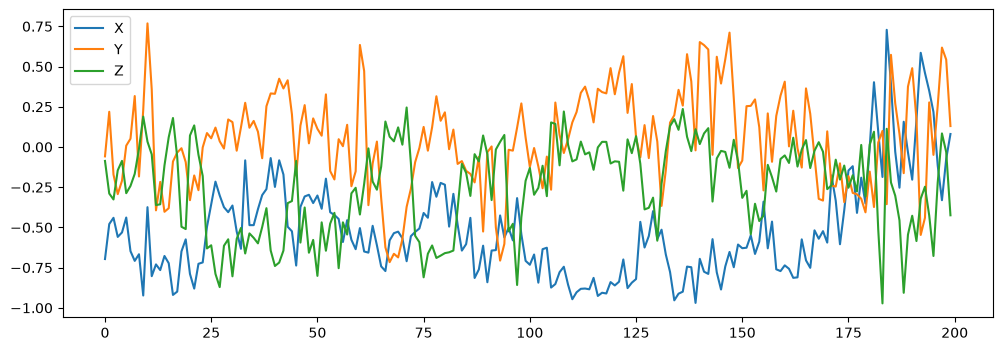

In [6]:
df_list[0][['X', 'Y', 'Z']].plot(figsize=(12, 4))

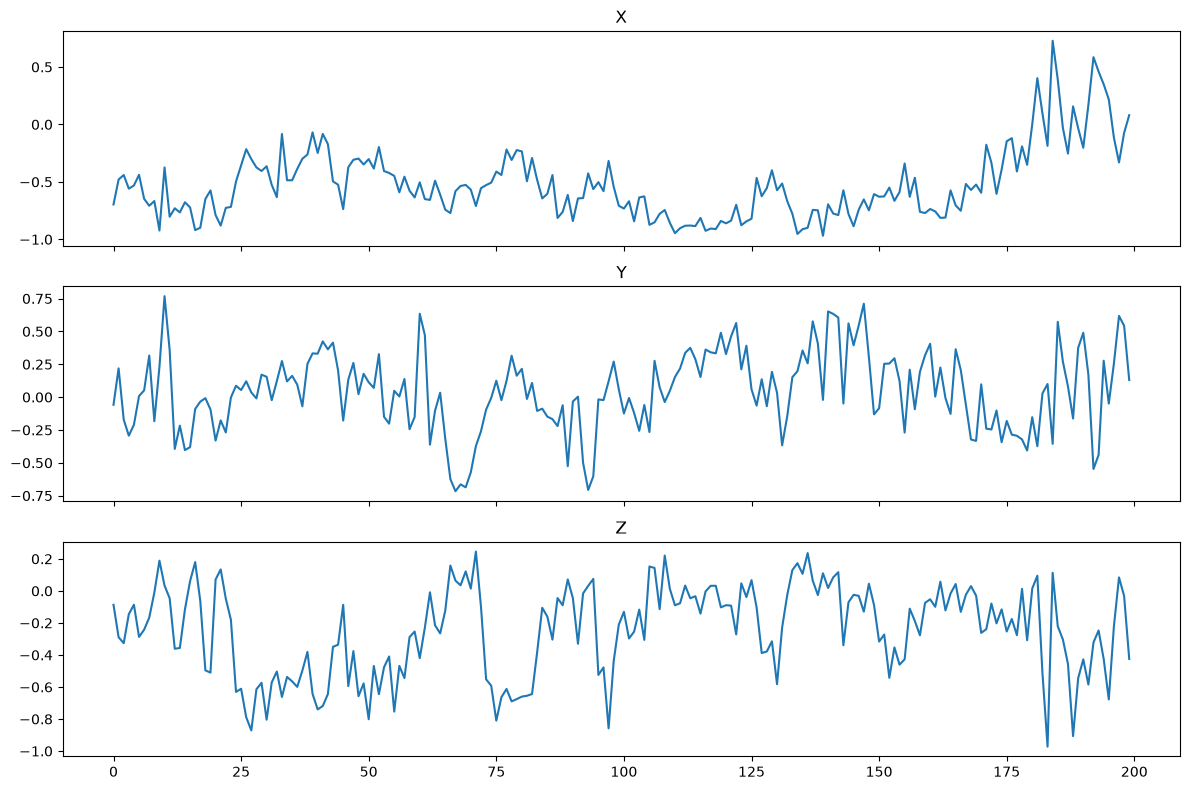

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
df_list[0]['X'].plot(ax=axes[0], title='X')
df_list[0]['Y'].plot(ax=axes[1], title='Y')
df_list[0]['Z'].plot(ax=axes[2], title='Z')
plt.tight_layout()
plt.show()

## EXPLORATION & PRE-PROCESSING: 

In [8]:
print(f"Numero di finestre (elementi della lista): {len(df_list)}")
print(f"Colonne: {df_list[0].columns.tolist()}")
print(f"Shape di una finestra: {df_list[0].shape}")

# lunghezza delle serie: sono tutte uguali?
lengths = pd.Series([d.shape[0] for d in df_list])
print(lengths.describe())

Numero di finestre (elementi della lista): 4437
Colonne: ['X', 'Y', 'Z', 'enmo', 'anglez', 'non-wear_flag', 'light', 'battery_voltage', 'weekday', 'quarter', 'relative_date_PCIAT', 'id', 'sii_binary']
Shape di una finestra: (200, 13)
count    4437.0
mean      200.0
std         0.0
min       200.0
25%       200.0
50%       200.0
75%       200.0
max       200.0
dtype: float64


**Risultato:** il dataset è una lista di **4437 finestre**, tutte lunghe esattamente 200 timestep. Secondo le istruzioni del dataset ogni timestep è una media su 30 minuti, ma come mostrato in P4 gli step si sovrappongono e una finestra copre circa **un ciclo giorno-notte**, non 100 ore contigue. Le 13 colonne sono:

- **8 variabili dinamiche** (cambiano a ogni timestep): `X`, `Y`, `Z` (accelerazione media sui tre assi, in g), `enmo` (movimento indipendente dalla direzione), `anglez` (angolo del polso rispetto all'orizzontale), `non-wear_flag` (quota del timestep in cui il dispositivo non è indossato), `light` (luce ambientale, lux), `battery_voltage` (mV);
- **3 variabili statiche** della finestra: `weekday`, `quarter`, `relative_date_PCIAT`;
- **identificativo e target**: `id` (soggetto) e `sii_binary` (0 = non problematico, 1 = problematico).

Attenzione: 4437 sono le finestre, non i soggetti. Come emerge più avanti, gli id unici sono solo 494.

In [9]:
# SBILANCIAMENTO CLASSI: per finestra e per soggetto (id)
sii_values = [d['sii_binary'].iloc[0] for d in df_list]
print("per finestra:", pd.Series(sii_values).value_counts(normalize=True).round(3).to_dict())

per_id = pd.Series(sii_values).groupby(ids_eda).first()
print("per id:      ", per_id.value_counts(normalize=True).round(3).to_dict(), f"(su {len(per_id)} id)")

per finestra: {0: 0.666, 1: 0.334}
per id:       {0: 0.609, 1: 0.391} (su 494 id)


**Risultato:** lo sbilanciamento è moderato, circa 2 a 1 a favore della classe 0, sia contando le finestre sia contando gli id (con gli id la classe 1 pesa un po' di più, perché i soggetti problematici hanno in media meno finestre). Non è necessario fare over/under-sampling, ma l'accuracy da sola è fuorviante: in valutazione useremo F1 macro, balanced accuracy e ROC-AUC, e uno split stratificato.

In [10]:
# check di range ed outliers evidenti 

df_all = pd.concat(df_list, ignore_index=True)
print(df_all[['X','Y','Z','enmo','anglez','light','battery_voltage']].describe())

""" 
ENMO --> euclidean norm minus one, è una misura che cattura X,Y e Z per calcolare quanto movimento c'è indipendemente dalla direzione MAX(sqrt(X**2, Y**2, Z**2) -1, 0) 
(quindi è normale che il dato possa essere zero, semplicemente il soggetto è rimasto fermo immobile per tutta la durata del timestep)

LIGHT --> misura il livello di luce ambientale (quindi anche questo può avere valore zero)

RANGE OSSERVATI (prima occhiata, poi approfonditi nelle celle seguenti):
- X: [-8.02, 1.36]   Y: [-2.08, 1.55]   Z: [-1.04, 8.02]
  per un accelerometro espresso in unità di gravità (g) ci aspetteremmo valori tipicamente in [-1, 1] 
  (fermo = ±1g su un asse): i minimi/massimi qui sopra sono già un indizio di possibili outlier puntuali,
  troppo isolati per essere visibili nel describe ma da quantificare con un controllo dedicato
- anglez: [-89.90, 89.75] --> range coerente con la definizione (angolo del polso rispetto al piano orizzontale,
  bounded per costruzione in [-90, 90]), quindi qui NON ci aspettiamo outlier fuori range
- battery_voltage: [3099, 6000] --> il minimo è plausibile per una batteria scarica, ma il massimo di 6000
  (numero "tondo" e molto lontano dal 75° percentile ~4005) è sospetto e va verificato
"""

                   X              Y              Z           enmo  \
count  887400.000000  887400.000000  887400.000000  887400.000000   
mean       -0.092578       0.003362      -0.091223       0.056764   
std         0.538622       0.358320       0.423530       0.084180   
min        -8.022103      -2.084078      -1.042407       0.000000   
25%        -0.571236      -0.230633      -0.364926       0.014106   
50%        -0.202865       0.002289      -0.114865       0.030716   
75%         0.435963       0.236372       0.152181       0.066491   
max         1.360524       1.552069       8.018888       7.033528   

              anglez          light  battery_voltage  
count  887400.000000  887400.000000    887400.000000  
mean       -6.642283      53.033760      3877.558594  
std        30.047264     208.232910       170.317795  
min       -89.903175       0.000000      3099.083252  
25%       -24.055105       3.105195      3782.000000  
50%        -7.890465       8.227631      3864.61

' \nENMO --> euclidean norm minus one, è una misura che cattura X,Y e Z per calcolare quanto movimento c\'è indipendemente dalla direzione MAX(sqrt(X**2, Y**2, Z**2) -1, 0) \n(quindi è normale che il dato possa essere zero, semplicemente il soggetto è rimasto fermo immobile per tutta la durata del timestep)\n\nLIGHT --> misura il livello di luce ambientale (quindi anche questo può avere valore zero)\n\nRANGE OSSERVATI (prima occhiata, poi approfonditi nelle celle seguenti):\n- X: [-8.02, 1.36]   Y: [-2.08, 1.55]   Z: [-1.04, 8.02]\n  per un accelerometro espresso in unità di gravità (g) ci aspetteremmo valori tipicamente in [-1, 1] \n  (fermo = ±1g su un asse): i minimi/massimi qui sopra sono già un indizio di possibili outlier puntuali,\n  troppo isolati per essere visibili nel describe ma da quantificare con un controllo dedicato\n- anglez: [-89.90, 89.75] --> range coerente con la definizione (angolo del polso rispetto al piano orizzontale,\n  bounded per costruzione in [-90, 90]), 

In [11]:
# OUTLIER PUNTUALI SU X, Y, Z: quantifichiamo quanto sono rari i valori fuori dal range fisico atteso [-1,1]g

for col, soglia in [('X', 3), ('Y', 3), ('Z', 3)]:
    n_estremi = (df_all[col].abs() > soglia).sum()
    print(f"{col}: {n_estremi} punti oltre |{soglia}|g su {len(df_all)} ({n_estremi/len(df_all)*100:.4f}%)")

punto_estremo = df_all.loc[df_all['X'] < -3, ['X','Y','Z','id']]
print("\nRiga con X più estremo:")
print(punto_estremo)

"""
il conto conferma che si tratta di outlier puntuali (POINT OUTLIER) isolatissimi: un solo timestamp su 887400
supera |3|g su X (arriva a -8.02g) e lo stesso vale per Z. È un singolo soggetto (id 1044), un solo istante:
troppo isolato per essere un problema sistematico di calibrazione del sensore, più coerente con un urto/scossone
improvviso oppure un glitch di lettura hardware in quell'istante.
Trattandosi di un singolo punto per un singolo soggetto, la strategia più sicura è NON eliminare l'intero soggetto
ma eventualmente clippare/interpolare solo quel timestep in fase di pre-processing, per non perdere le altre 199
osservazioni valide di quella time series.
"""

X: 1 punti oltre |3|g su 887400 (0.0001%)
Y: 0 punti oltre |3|g su 887400 (0.0000%)
Z: 1 punti oltre |3|g su 887400 (0.0001%)

Riga con X più estremo:
               X         Y         Z    id
602550 -8.022103  0.370451 -0.214102  1044


"\nil conto conferma che si tratta di outlier puntuali (POINT OUTLIER) isolatissimi: un solo timestamp su 887400\nsupera |3|g su X (arriva a -8.02g) e lo stesso vale per Z. È un singolo soggetto (id 1044), un solo istante:\ntroppo isolato per essere un problema sistematico di calibrazione del sensore, più coerente con un urto/scossone\nimprovviso oppure un glitch di lettura hardware in quell'istante.\nTrattandosi di un singolo punto per un singolo soggetto, la strategia più sicura è NON eliminare l'intero soggetto\nma eventualmente clippare/interpolare solo quel timestep in fase di pre-processing, per non perdere le altre 199\nosservazioni valide di quella time series.\n"

In [12]:
# OUTLIER SU battery_voltage: il massimo di 6000 è un valore plausibile o un placeholder/glitch del sensore?

bv = df_all['battery_voltage']
print("valori > 5000 mV:", (bv > 5000).sum(), "su", len(bv))
print(df_all.loc[bv > 5000, ['battery_voltage','id']])

"""
solo 4 osservazioni su 887400 superano i 5000 mV, e sono tutte concentrate in un'unica finestra/soggetto (id 3539),
non sparse a caso nel dataset. Il valore massimo è esattamente 6000.0 (numero tondo, ripetuto due volte) mentre
il resto della distribuzione sta comodamente fra 3099 e ~4300 mV: questo pattern (poche osservazioni, valore tondo,
concentrate in un solo soggetto) è tipico sia di un errore di telemetria del sensore sia di un valore "di comodo"
scritto dal firmware quando la lettura reale non è disponibile (un placeholder mascherato da valore numerico
plausibile, non da un codice ovvio tipo -1 o 999). Da tenere in considerazione: se si userà battery_voltage come
feature di QC, conviene clippare questi 4 valori o trattarli come missing, altrimenti rischiano di distorcere
una eventuale normalizzazione (es. min-max scaling) calcolata su tutto il dataset.
"""

valori > 5000 mV: 4 su 887400
        battery_voltage    id
230170      5622.481934  3539
230171      6000.000000  3539
230172      6000.000000  3539
230174      5248.975098  3539


'\nsolo 4 osservazioni su 887400 superano i 5000 mV, e sono tutte concentrate in un\'unica finestra/soggetto (id 3539),\nnon sparse a caso nel dataset. Il valore massimo è esattamente 6000.0 (numero tondo, ripetuto due volte) mentre\nil resto della distribuzione sta comodamente fra 3099 e ~4300 mV: questo pattern (poche osservazioni, valore tondo,\nconcentrate in un solo soggetto) è tipico sia di un errore di telemetria del sensore sia di un valore "di comodo"\nscritto dal firmware quando la lettura reale non è disponibile (un placeholder mascherato da valore numerico\nplausibile, non da un codice ovvio tipo -1 o 999). Da tenere in considerazione: se si userà battery_voltage come\nfeature di QC, conviene clippare questi 4 valori o trattarli come missing, altrimenti rischiano di distorcere\nuna eventuale normalizzazione (es. min-max scaling) calcolata su tutto il dataset.\n'

In [13]:
# OUTLIER SU light: la coda destra è molto lunga, ma sono errori o semplice esposizione al sole?

light = df_all['light']
print("light > 500 lux:", (light > 500).sum(), f"({(light>500).mean()*100:.2f}%)")
print("light > 1000 lux:", (light > 1000).sum(), f"({(light>1000).mean()*100:.2f}%)")
print("light > 2000 lux:", (light > 2000).sum(), f"({(light>2000).mean()*100:.2f}%)")
print("\ntop 5 valori più alti e relativo soggetto:")
print(df_all.sort_values('light', ascending=False)[['light','id']].head(5))

"""
a differenza di battery_voltage, qui i valori estremi NON sono isolati: ci sono migliaia di osservazioni sopra i
500 lux e i valori più alti (~2500-2594 lux) ricorrono più volte per gli stessi soggetti (es. id 745, 3309).
Questo è un pattern coerente con luce solare diretta reale (l'illuminamento in esterno in una giornata di sole
può superare facilmente i 10000 lux), non con un errore di misura: quindi li trattiamo come EXTREME VALUES
genuini e non come MISTAKES da correggere. Il problema pratico non è la correttezza del dato ma la sua scala:
la distribuzione di light è fortemente right-skewed (mediana ~8.2 contro una coda che arriva a 2594), quindi
per un eventuale uso come feature conviene una trasformazione tipo log1p prima di normalizzare, altrimenti pochi
picchi dominerebbero la scala della variabile.
"""

light > 500 lux: 24028 (2.71%)
light > 1000 lux: 12816 (1.44%)
light > 2000 lux: 1883 (0.21%)

top 5 valori più alti e relativo soggetto:
              light    id
255475  2594.622070   745
814511  2594.008301   745
814507  2584.750244   745
814508  2572.192383   745
493320  2571.300049  3309


"\na differenza di battery_voltage, qui i valori estremi NON sono isolati: ci sono migliaia di osservazioni sopra i\n500 lux e i valori più alti (~2500-2594 lux) ricorrono più volte per gli stessi soggetti (es. id 745, 3309).\nQuesto è un pattern coerente con luce solare diretta reale (l'illuminamento in esterno in una giornata di sole\npuò superare facilmente i 10000 lux), non con un errore di misura: quindi li trattiamo come EXTREME VALUES\ngenuini e non come MISTAKES da correggere. Il problema pratico non è la correttezza del dato ma la sua scala:\nla distribuzione di light è fortemente right-skewed (mediana ~8.2 contro una coda che arriva a 2594), quindi\nper un eventuale uso come feature conviene una trasformazione tipo log1p prima di normalizzare, altrimenti pochi\npicchi dominerebbero la scala della variabile.\n"

In [14]:
# PLACEHOLDER CHECK su feature "categoriche": weekday, quarter, relative_date_PCIAT, non-wear_flag
# cerchiamo codici sentinella tipici dei placeholder (es. -1, 0 fuori contesto, 999, 9999)

print("weekday - valori unici:", sorted(df_all['weekday'].unique()))
print("quarter - valori unici:", sorted(df_all['quarter'].unique()))
print("relative_date_PCIAT - min/max:", df_all['relative_date_PCIAT'].min(), df_all['relative_date_PCIAT'].max())

frac_fraz = ((df_all['non-wear_flag'] > 0) & (df_all['non-wear_flag'] < 1)).mean()
print(f"non-wear_flag - % di valori strettamente fra 0 e 1: {frac_fraz*100:.3f}%")
print("non-wear_flag - valori unici (sono solo 13 in tutto il dataset!):", sorted(df_all['non-wear_flag'].unique()))

"""
- weekday: solo valori 1-7, nessun codice fuori range → nessun placeholder, è costante dentro ogni finestra
  (già visto sopra) ma cambia fra le finestre dello stesso soggetto: è un metadato della finestra, non "sporco"
- quarter: solo valori 1-4, stesso discorso di weekday, nessun placeholder
- relative_date_PCIAT: range [-102, 495]. Il minimo negativo NON è un errore: rappresenta soggetti la cui
  registrazione è iniziata prima della data della valutazione PCIAT (quindi giorni "prima" dell'assessment),
  è un valore plausibile per una feature relativa a una data, non un placeholder
- non-wear_flag: conferma quantitativa dell'ipotesi fatta sopra, solo lo 0.24% dei valori è strettamente fra 0 e 1,
  e in totale esistono solo 13 valori unici nell'intero dataset: NON è quindi un flag binario "sporco" ma una
  fraction of wear-time con granularità limitata (probabilmente calcolata su sotto-intervalli fissi dei 30 minuti),
  nessun placeholder da correggere, solo da tenerne conto nell'interpretazione (0.83 non è "quasi indossato",
  è "indossato per l'83% della finestra")
"""

weekday - valori unici: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0)]
quarter - valori unici: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
relative_date_PCIAT - min/max: -102.0 495.0
non-wear_flag - % di valori strettamente fra 0 e 1: 0.238%


non-wear_flag - valori unici (sono solo 13 in tutto il dataset!): [np.float32(0.0), np.float32(0.108333334), np.float32(0.1638889), np.float32(0.16944446), np.float32(0.49722224), np.float32(0.49745762), np.float32(0.50277776), np.float32(0.5138889), np.float32(0.82222223), np.float32(0.83055556), np.float32(0.83247125), np.float32(0.8361111), np.float32(1.0)]


'\n- weekday: solo valori 1-7, nessun codice fuori range → nessun placeholder, è costante dentro ogni finestra\n  (già visto sopra) ma cambia fra le finestre dello stesso soggetto: è un metadato della finestra, non "sporco"\n- quarter: solo valori 1-4, stesso discorso di weekday, nessun placeholder\n- relative_date_PCIAT: range [-102, 495]. Il minimo negativo NON è un errore: rappresenta soggetti la cui\n  registrazione è iniziata prima della data della valutazione PCIAT (quindi giorni "prima" dell\'assessment),\n  è un valore plausibile per una feature relativa a una data, non un placeholder\n- non-wear_flag: conferma quantitativa dell\'ipotesi fatta sopra, solo lo 0.24% dei valori è strettamente fra 0 e 1,\n  e in totale esistono solo 13 valori unici nell\'intero dataset: NON è quindi un flag binario "sporco" ma una\n  fraction of wear-time con granularità limitata (probabilmente calcolata su sotto-intervalli fissi dei 30 minuti),\n  nessun placeholder da correggere, solo da tenerne 

In [15]:
# APPLICHIAMO IL METODO MAD VISTO in teoria (mediana ± 3*MAD) su enmo, per vedere quanti punti verrebbero
# flaggati come outlier statistici puri, senza alcuna informazione di dominio

med = df_all['enmo'].median()
mad = (df_all['enmo'] - med).abs().median()
lower, upper = med - 3*mad, med + 3*mad
n_out = ((df_all['enmo'] < lower) | (df_all['enmo'] > upper)).sum()
print(f"mediana={med:.4f}  MAD={mad:.4f}  intervallo=[{lower:.4f}, {upper:.4f}]")
print(f"punti fuori intervallo: {n_out} su {len(df_all)} ({n_out/len(df_all)*100:.2f}%)")

"""
il metodo MAD, applicato "alla lettera", marca come outlier circa il 16% dei punti di enmo: un numero enorme
per essere considerato outlier puntuali. Questo NON significa che il 16% dei dati sia sporco, significa che
enmo ha una distribuzione fortemente asimmetrica (quasi tutta concentrata vicino a 0, con una coda lunga di
movimento attivo) e un metodo pensato per dati "circa gaussiani" come il MAD standard è troppo aggressivo su
questo tipo di segnale. Conferma quanto visto nella teoria: la scelta del metodo di outlier detection deve
dipendere dalla forma della distribuzione, qui ha più senso ragionare in termini di range fisico plausibile
(come fatto per X/Y/Z sopra) che di soglie statistiche generiche pensate per dati simmetrici.
"""

mediana=0.0307  MAD=0.0209  intervallo=[-0.0319, 0.0933]
punti fuori intervallo: 144853 su 887400 (16.32%)


'\nil metodo MAD, applicato "alla lettera", marca come outlier circa il 16% dei punti di enmo: un numero enorme\nper essere considerato outlier puntuali. Questo NON significa che il 16% dei dati sia sporco, significa che\nenmo ha una distribuzione fortemente asimmetrica (quasi tutta concentrata vicino a 0, con una coda lunga di\nmovimento attivo) e un metodo pensato per dati "circa gaussiani" come il MAD standard è troppo aggressivo su\nquesto tipo di segnale. Conferma quanto visto nella teoria: la scelta del metodo di outlier detection deve\ndipendere dalla forma della distribuzione, qui ha più senso ragionare in termini di range fisico plausibile\n(come fatto per X/Y/Z sopra) che di soglie statistiche generiche pensate per dati simmetrici.\n'

In [16]:
# CONTROLLO "SENSORE BLOCCATO": possibili placeholder di riempimento nascosti come sequenze di valori
# consecutivi identici (tipico artefatto quando un sensore smette di aggiornarsi e l'ultimo valore viene ripetuto)

max_run_lengths = []
for d in df_list:
    x = d['X'].values
    run = best = 1
    for i in range(1, len(x)):
        run = run + 1 if x[i] == x[i-1] else 1
        best = max(best, run)
    max_run_lengths.append(best)

print(pd.Series(max_run_lengths).describe())
print("soggetti con almeno 10 valori consecutivi identici:", (pd.Series(max_run_lengths) >= 10).sum())

"""
nessun soggetto ha più di 2 valori consecutivi identici su X: significa che non ci sono segmenti "flat"
(sensore bloccato/placeholder di riempimento mascherato da valore costante), un artefatto molto comune nei
dati da wearable ma che qui possiamo escludere. Insieme al fatto che i missing values sono zero ovunque (verificato
più avanti), questo rafforza l'idea che il dataset sia già stato ripulito/pre-processato a monte rispetto al
segnale grezzo originale.
"""

count    4437.000000
mean        1.006987
std         0.083303
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         2.000000
dtype: float64
soggetti con almeno 10 valori consecutivi identici: 0


'\nnessun soggetto ha più di 2 valori consecutivi identici su X: significa che non ci sono segmenti "flat"\n(sensore bloccato/placeholder di riempimento mascherato da valore costante), un artefatto molto comune nei\ndati da wearable ma che qui possiamo escludere. Insieme al fatto che i missing values sono zero ovunque (verificato\npiù avanti), questo rafforza l\'idea che il dataset sia già stato ripulito/pre-processato a monte rispetto al\nsegnale grezzo originale.\n'

In [17]:
# BONUS - STRUTTURA DEL DATASET: quante time series per soggetto reale?
# lo controlliamo perché durante l'audit sui placeholder abbiamo notato che "id" si ripete molto più spesso
# di quanto ci si aspetterebbe se ogni elemento di df_list fosse un soggetto diverso

n_finestre = len(df_list)
n_id_unici = df_all['id'].nunique()
finestre_per_id = df_all.groupby('id').size() / 200

print(f"finestre totali (len(df_list)): {n_finestre}")
print(f"soggetti realmente unici (id unici): {n_id_unici}")
print(finestre_per_id.describe())

"""
scoperta IMPORTANTE che non è un outlier ma riguarda l'integrità del dataset: i 4437 elementi della lista
sono FINESTRE temporali e non soggetti, ma provengono da soli 494 id unici (in media ~9 finestre per id, fino
a un massimo di 36 finestre per lo stesso id, mentre 241 id compaiono una sola volta). In pratica lo stesso
ragazzino compare più volte nel dataset con finestre diverse (probabilmente giorni diversi della stessa
registrazione lunga, "tagliata" in blocchi da 200 step).
Implicazione pratica per il resto del progetto: in fase di train/test split NON si può splittare a caso per
riga/finestra, perché finestre dello stesso id finirebbero sia in train che in test, causando data leakage
(il modello "riconoscerebbe" il soggetto invece di generalizzare sul comportamento). Lo split va fatto
raggruppando per id (es. GroupShuffleSplit / GroupKFold di scikit-learn).
"""

finestre totali (len(df_list)): 4437
soggetti realmente unici (id unici): 494
count    494.000000
mean       8.981781
std       10.485461
min        1.000000
25%        1.000000
50%        2.000000
75%       17.750000
max       36.000000
dtype: float64


'\nscoperta IMPORTANTE che non è un outlier ma riguarda l\'integrità del dataset: i 4437 elementi della lista\nsono FINESTRE temporali e non soggetti, ma provengono da soli 494 id unici (in media ~9 finestre per id, fino\na un massimo di 36 finestre per lo stesso id, mentre 241 id compaiono una sola volta). In pratica lo stesso\nragazzino compare più volte nel dataset con finestre diverse (probabilmente giorni diversi della stessa\nregistrazione lunga, "tagliata" in blocchi da 200 step).\nImplicazione pratica per il resto del progetto: in fase di train/test split NON si può splittare a caso per\nriga/finestra, perché finestre dello stesso id finirebbero sia in train che in test, causando data leakage\n(il modello "riconoscerebbe" il soggetto invece di generalizzare sul comportamento). Lo split va fatto\nraggruppando per id (es. GroupShuffleSplit / GroupKFold di scikit-learn).\n'

' \nda questo grafico evince che la luce ambientale è quasi semore bassa a parte per due picchi giornalieri, \nquesto potrebbe essere semplicemente perchè il sensore è sempre coperto (es. manica della felpa),\n sennò non avrebbe senso che un ragazzino si muova così tanto tempo al buio pure durante le ore solari\n'

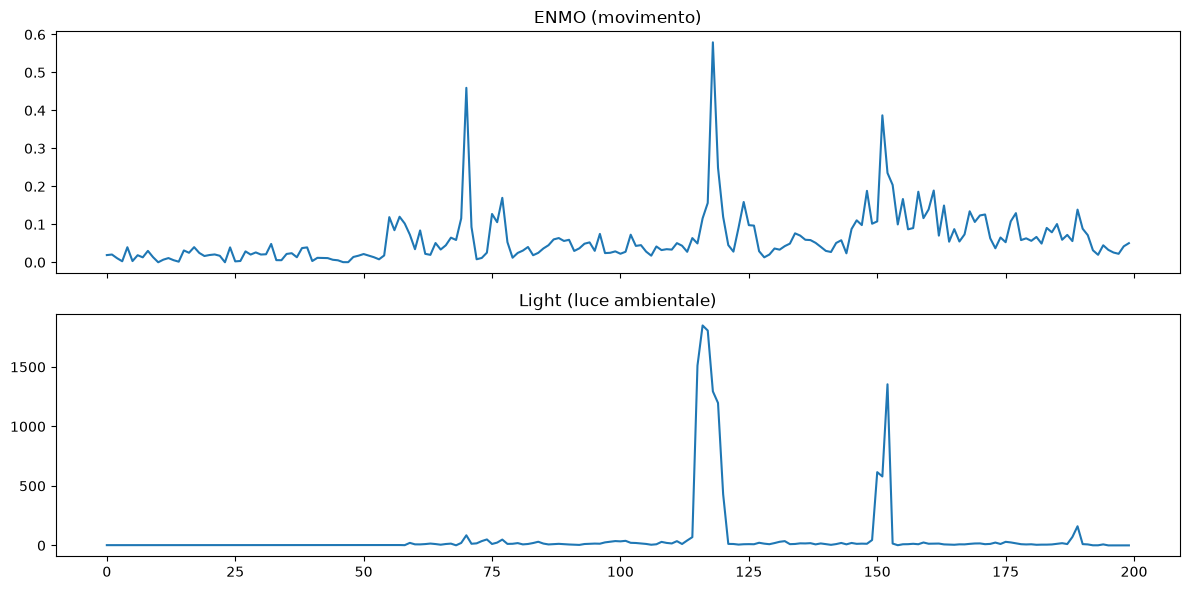

In [18]:
import matplotlib.pyplot as plt
""" andiamo a vedere se chi sta fermo lo fa alla luce oppure al buio """
fig, ax = plt.subplots(2, 1, figsize=(12,6), sharex=True)
df_list[2]['enmo'].plot(ax=ax[0], title='ENMO (movimento)')
df_list[2]['light'].plot(ax=ax[1], title='Light (luce ambientale)')
plt.tight_layout()

""" 
da questo grafico evince che la luce ambientale è quasi semore bassa a parte per due picchi giornalieri, 
questo potrebbe essere semplicemente perchè il sensore è sempre coperto (es. manica della felpa),
 sennò non avrebbe senso che un ragazzino si muova così tanto tempo al buio pure durante le ore solari
"""

# POTREMMO VALORE DI ELIMINARE LIGHT DALLE VARIABILI (però ho analizzato un singolo soggetto devo allargare l'analisi)

In [19]:
light_zero_pct = []
for d in df_list:
    pct = (d['light'] < 5).mean()  # soglia bassa, "quasi buio"
    light_zero_pct.append(pct)

pd.Series(light_zero_pct).describe()

count    4437.000000
mean        0.362022
std         0.198300
min         0.000000
25%         0.215000
50%         0.340000
75%         0.475000
max         1.000000
dtype: float64

In [20]:
# non-wear_flag 
somma_1 = 0
somma_0 = 0
altro = []

for d in df_list:
    for val in d["non-wear_flag"]:
        if val == 1:
            somma_1 += 1
        elif val == 0:
            somma_0 += 1
        else:
            altro.append(val)

print("somma_1:",somma_1, "somma_0:",somma_0,  " \n altro:", altro)

""" 
i numeri compresi fra 0 ed 1 non sono da ingorare ma probabilmente sono percentuali di quanto il braccialetto è stato indoddato in quell'intervallo di 30 min 
"""


somma_1: 22979 somma_0: 862305  
 altro: [0.8361111283302307, 0.5027777552604675, 0.16944445669651031, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.8361111283302307, 0.5027777552604675, 0.16944445669651031, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.8361111283302307, 0.5027777552604675, 0.16944445669651031, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.8361111283302307, 0.5027777552604675, 0.16944445669651031, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.8361111283302307, 0.5027777552604675, 0.16944445669651031, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.8361111283302307, 0.5027777552604675, 0.16944445669651031, 0.16388890147209167, 0.49722224473953247, 0.8305555582046509, 0.8361111283302307, 0.5027777552604675, 0.16944445669651031, 0.8361111283302307, 0.5027777552604

" \ni numeri compresi fra 0 ed 1 non sono da ingorare ma probabilmente sono percentuali di quanto il braccialetto è stato indoddato in quell'intervallo di 30 min \n"

## VISUALIZZAZIONI E DATA UNDERSTANDING (continua)

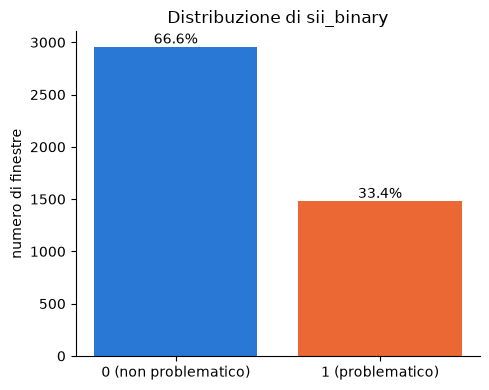

0    2957
1    1480
Name: count, dtype: int64


"\nconferma visiva dello sbilanciamento moderato già osservato sopra: 2957 finestre in classe 0 (66.6%) contro\n1480 in classe 1 (33.4%), un rapporto di circa 2 a 1. Non è uno sbilanciamento estremo (tipo 95/5) ma è\nabbastanza da rendere l'accuracy una metrica fuorviante: un classificatore banale che predice sempre 0\notterrebbe già il 66.6% di accuracy senza aver imparato nulla. Per questo, come notato sopra, conviene\nvalutare con F1/ROC-AUC (meglio ancora F1 macro o balanced accuracy) e usare uno stratified split per\nmantenere questa stessa proporzione identica fra train e test (da fare insieme al raggruppamento per id\nvisto più avanti, per evitare sia lo sbilanciamento sia il leakage).\n"

In [21]:
# BILANCIAMENTO CLASSI - visualizzazione
sii_counts = pd.Series(sii_values).value_counts().sort_index()
sii_pct = pd.Series(sii_values).value_counts(normalize=True).sort_index()

colors = ['#2a78d6', '#eb6834']  # 0 = non problematico, 1 = problematico

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['0 (non problematico)', '1 (problematico)'], sii_counts.values, color=colors)
for bar, pct in zip(bars, sii_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{pct:.1%}', ha='center', va='bottom')
ax.set_ylabel('numero di finestre')
ax.set_title('Distribuzione di sii_binary')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(sii_counts)

"""
conferma visiva dello sbilanciamento moderato già osservato sopra: 2957 finestre in classe 0 (66.6%) contro
1480 in classe 1 (33.4%), un rapporto di circa 2 a 1. Non è uno sbilanciamento estremo (tipo 95/5) ma è
abbastanza da rendere l'accuracy una metrica fuorviante: un classificatore banale che predice sempre 0
otterrebbe già il 66.6% di accuracy senza aver imparato nulla. Per questo, come notato sopra, conviene
valutare con F1/ROC-AUC (meglio ancora F1 macro o balanced accuracy) e usare uno stratified split per
mantenere questa stessa proporzione identica fra train e test (da fare insieme al raggruppamento per id
visto più avanti, per evitare sia lo sbilanciamento sia il leakage).
"""

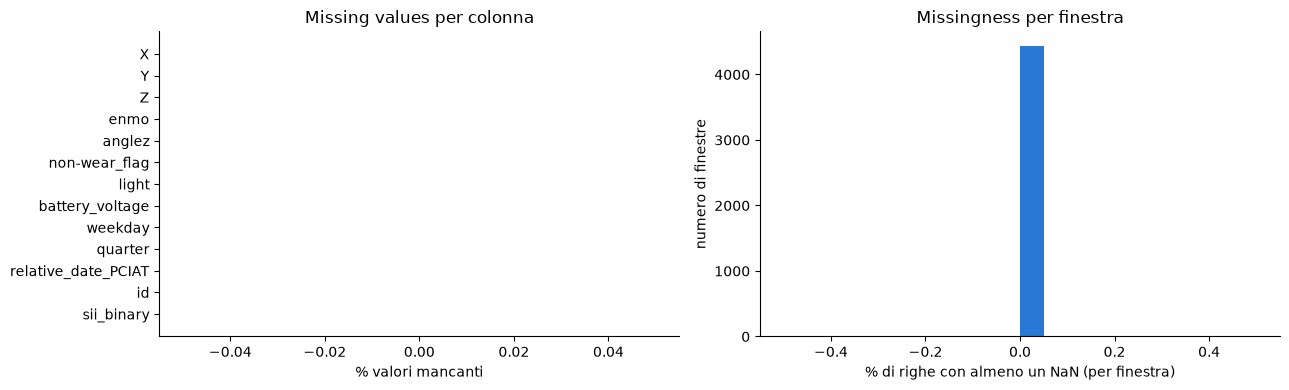

'\nsia il barh a sinistra che l\'istogramma a destra sono completamente vuoti/a zero: missing_pct è 0.0 per TUTTE\nle colonne e missing_per_subject è 0.0 per TUTTE le 4437 finestre (min=max=0 nel describe qui sopra).\nIl dataset è quindi già completamente pulito rispetto ai NaN, probabilmente perché derivato da un pre-processing\na monte (i dati raw dei wearable difficilmente non hanno mai buchi). Questo sposta l\'attenzione della data\nunderstanding da "come imputare i missing" (il tema centrale della teoria a inizio notebook) a due problemi\ndiversi ma collegati: (1) valori "silenziosi" che potrebbero sostituire i missing con uno zero plausibile invece\ndi NaN (es. enmo o light a 0 non distinguibile da un vero valore di quiete/buio), e (2) outlier/placeholder\nmascherati da numeri validi, che è esattamente quello che abbiamo controllato nelle celle precedenti su\nX/Y/Z, battery_voltage e light.\n'

In [22]:
# MISSING VALUES - overview
missing_pct = df_all.isna().mean().sort_values(ascending=False) * 100
missing_per_subject = pd.Series([d.isna().any(axis=1).mean() for d in df_list])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].barh(missing_pct.index[::-1], missing_pct.values[::-1], color='#2a78d6')
axes[0].set_xlabel('% valori mancanti')
axes[0].set_title('Missing values per colonna')
axes[0].spines[['top', 'right']].set_visible(False)

axes[1].hist(missing_per_subject.values, bins=20, color='#2a78d6')
axes[1].set_xlabel('% di righe con almeno un NaN (per finestra)')
axes[1].set_ylabel('numero di finestre')
axes[1].set_title('Missingness per finestra')
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

missing_per_subject.describe()

"""
sia il barh a sinistra che l'istogramma a destra sono completamente vuoti/a zero: missing_pct è 0.0 per TUTTE
le colonne e missing_per_subject è 0.0 per TUTTE le 4437 finestre (min=max=0 nel describe qui sopra).
Il dataset è quindi già completamente pulito rispetto ai NaN, probabilmente perché derivato da un pre-processing
a monte (i dati raw dei wearable difficilmente non hanno mai buchi). Questo sposta l'attenzione della data
understanding da "come imputare i missing" (il tema centrale della teoria a inizio notebook) a due problemi
diversi ma collegati: (1) valori "silenziosi" che potrebbero sostituire i missing con uno zero plausibile invece
di NaN (es. enmo o light a 0 non distinguibile da un vero valore di quiete/buio), e (2) outlier/placeholder
mascherati da numeri validi, che è esattamente quello che abbiamo controllato nelle celle precedenti su
X/Y/Z, battery_voltage e light.
"""

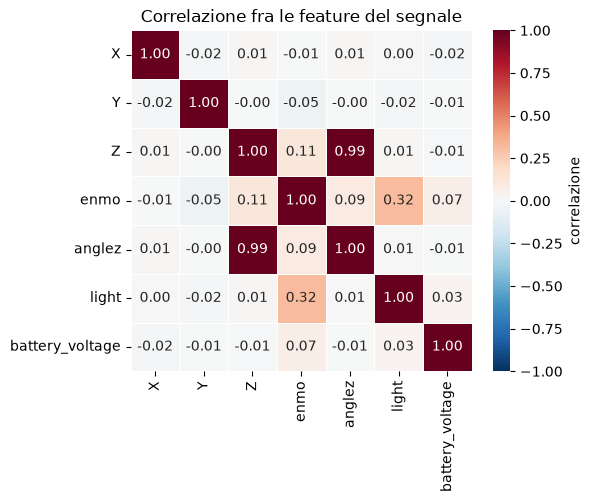

'\nenmo dovrebbe essere derivato da X, Y, Z quindi ci aspettiamo una certa ridondanza:\nutile per capire se X/Y/Z grezzi aggiungono informazione oltre enmo/anglez o sono ridondanti\ne quindi eliminabili in fase di data manipulation\n\nCOSA SI VEDE NELLA HEATMAP:\n- Z e anglez sono correlati quasi perfettamente (0.99): non è un caso, anglez è calcolato matematicamente\n  a partire (soprattutto) da Z (arctan della componente verticale), quindi le due feature portano quasi la\n  stessa informazione → tenerle entrambe in un modello lineare sarebbe ridondante/rischio di collinearità\n- enmo correla solo debolmente con Z (0.11) e per nulla con X/Y (~0), il che ha senso: enmo è pensato per\n  essere invariante alla direzione del movimento (è una norma), quindi "assorbe" l\'informazione di tutti e\n  tre gli assi senza dipendere fortemente da uno in particolare\n- enmo e light hanno una correlazione moderata (0.32), la più alta fra feature "non ovviamente collegate":\n  conferma quantitativame

In [23]:
# CORRELAZIONE TRA I SEGNALI
cols = ['X', 'Y', 'Z', 'enmo', 'anglez', 'light', 'battery_voltage']
corr = df_all[cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'correlazione'}, ax=ax)
ax.set_title('Correlazione fra le feature del segnale')
plt.tight_layout()
plt.show()

"""
enmo dovrebbe essere derivato da X, Y, Z quindi ci aspettiamo una certa ridondanza:
utile per capire se X/Y/Z grezzi aggiungono informazione oltre enmo/anglez o sono ridondanti
e quindi eliminabili in fase di data manipulation

COSA SI VEDE NELLA HEATMAP:
- Z e anglez sono correlati quasi perfettamente (0.99): non è un caso, anglez è calcolato matematicamente
  a partire (soprattutto) da Z (arctan della componente verticale), quindi le due feature portano quasi la
  stessa informazione → tenerle entrambe in un modello lineare sarebbe ridondante/rischio di collinearità
- enmo correla solo debolmente con Z (0.11) e per nulla con X/Y (~0), il che ha senso: enmo è pensato per
  essere invariante alla direzione del movimento (è una norma), quindi "assorbe" l'informazione di tutti e
  tre gli assi senza dipendere fortemente da uno in particolare
- enmo e light hanno una correlazione moderata (0.32), la più alta fra feature "non ovviamente collegate":
  conferma quantitativamente l'intuizione avuta guardando il singolo soggetto sopra (chi si muove di più
  tende anche ad essere più esposto alla luce, es. attività diurna/outdoor vs riposo notturno al buio)
- X e Y sono praticamente scorrelati da tutto (valori vicini a 0 su tutta la riga/colonna): non sono ridondanti
  con enmo/anglez, contengono informazione di orientamento/direzione che le feature derivate buttano via,
  quindi eliminarli a priori sarebbe una perdita di informazione, non solo una semplice pulizia
- battery_voltage è scorrelato linearmente con tutti i segnali (valori vicini a 0): rassicurante dal punto di
  vista del leakage lineare, verifica che verrà approfondita più avanti guardando anche il trend temporale e
  il confronto diretto fra le due classi
"""

### Investigation: why are `Z` and `anglez` correlated at 0.99?

The correlation heatmap above shows an almost perfect correlation (0.99) between the raw Z-axis accelerometer reading and the derived `anglez` feature. Before treating this as "these two columns carry the same information, drop one", it's worth understanding **why** this happens — the explanation changes what we should actually do about it.

**Hypothesis to test:** maybe X and Y barely move during the recording, so `anglez` — which in principle combines all three axes — ends up reflecting almost only Z simply because X and Y are close to constant.

**Plan to test it (4 steps):**
1. Plot X, Y, Z and anglez for the same subject/window, to see if their shapes visually line up.
2. Compare the standard deviation of X, Y and Z — if the hypothesis is right, X and Y should have a much smaller std than Z.
3. Recompute `anglez` from the raw X, Y, Z values using the standard wearable-accelerometer formula (the one used e.g. by the GGIR R package, a common preprocessing pipeline for this kind of actigraphy data) and compare it to the `anglez` column already present in the dataset.
4. Scatter-plot `anglez` against each of X, Y, Z individually, to visualize how much each single axis explains `anglez` on its own.

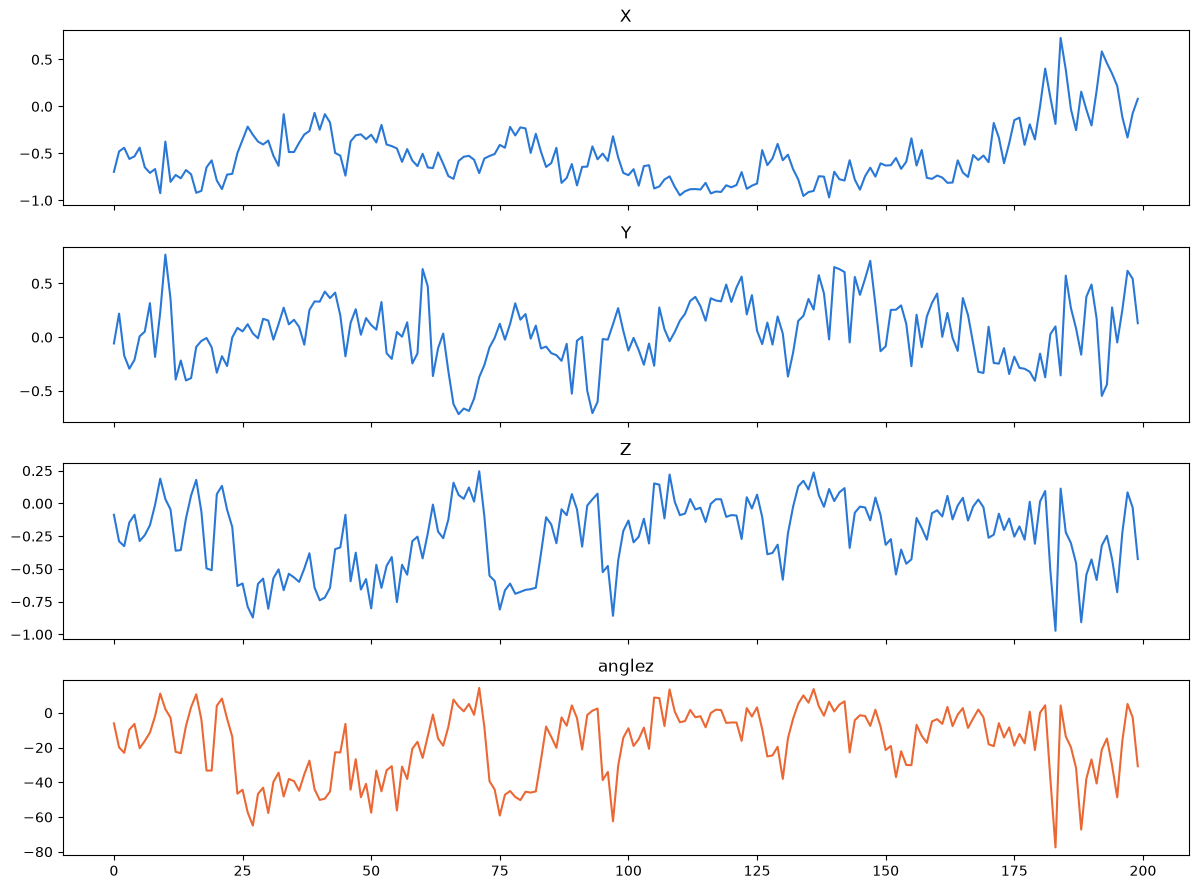

"\nRESULT: the Z panel and the anglez panel are visually almost superimposable — every local minimum/maximum\nin Z (e.g. around timestep 25, 70, 95, and the sharp double-dip around timestep 180) shows up at the exact\nsame timesteps in anglez, just rescaled from a [-1, 1]-ish range to a [-90, 90] degree range. X and Y, on\nthe other hand, follow a visibly different, independent trajectory (their peaks/dips do not line up with\nanglez's peaks/dips). This is already strong visual evidence that anglez is driven almost entirely by Z.\n"

In [24]:
# STEP 1 — visual comparison of the 4 raw signals for one subject (same subject as the very first
# plot in the notebook), over the same 200 timesteps, stacked so their shapes can be compared directly.
# What we are looking for: does the anglez curve (bottom, orange) trace the same ups/downs as Z (blue,
# third row), while looking unrelated to X and Y (blue, first two rows)?
subj = 0
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, col, color in zip(axes, ['X', 'Y', 'Z', 'anglez'], ['#2a78d6', '#2a78d6', '#2a78d6', '#eb6834']):
    df_list[subj][col].plot(ax=ax, title=col, color=color)
plt.tight_layout()
plt.show()

"""
RESULT: the Z panel and the anglez panel are visually almost superimposable — every local minimum/maximum
in Z (e.g. around timestep 25, 70, 95, and the sharp double-dip around timestep 180) shows up at the exact
same timesteps in anglez, just rescaled from a [-1, 1]-ish range to a [-90, 90] degree range. X and Y, on
the other hand, follow a visibly different, independent trajectory (their peaks/dips do not line up with
anglez's peaks/dips). This is already strong visual evidence that anglez is driven almost entirely by Z.
"""

In [25]:
# STEP 2 — quantitative check of the hypothesis "X and Y barely move / are close to constant, so Z
# dominates by default". If that hypothesis were correct, we would expect std(X) and std(Y) to be much
# smaller than std(Z). We measure this on the FULL dataset (df_all), not just one subject, so the result
# generalizes instead of being an artifact of the one subject plotted above.
print(df_all[['X', 'Y', 'Z']].std())

X    0.538622
Y    0.358320
Z    0.423530
dtype: float32


**Result of step 2 — the hypothesis, as stated, is NOT supported by the data:**

```
X    0.538622
Y    0.358320
Z    0.423530
```

The standard deviation of X (0.54) is actually **higher** than that of Z (0.42), and even Y (0.36) is not dramatically smaller than Z. So X and Y are not "sitting still" while Z moves — all three axes move by a broadly comparable amount. The "X/Y barely move" explanation does not hold up numerically.

**So what is actually going on?** The real reason is not about how much each axis *moves*, it's about how `anglez` is **mathematically defined** from X, Y, Z in the first place. In wearable-accelerometer pipelines (this is the standard definition used e.g. by the GGIR R package, which this kind of actigraphy dataset is commonly preprocessed with), the wrist angle relative to the horizontal plane is computed as:

$$\text{anglez} = \arctan\!\left(\frac{Z}{\sqrt{X^2 + Y^2}}\right) \cdot \frac{180}{\pi}$$

Look at where each axis appears in this formula:
- **Z appears alone in the numerator.** Its sign and magnitude directly control the sign and magnitude of the angle. A change in Z almost linearly moves the arctan output (for the range of values seen here).
- **X and Y appear only inside `sqrt(X^2 + Y^2)`, combined into a single non-negative magnitude, in the denominator.** Squaring and summing them together destroys their individual direction/sign information — the formula literally cannot tell whether the wrist rotated "more towards X" or "more towards Y", it only cares about their combined magnitude, and even that magnitude has a comparatively muted effect on the arctan output compared to Z.

In other words: it's not that X and Y are *physically* flat, it's that the formula that defines anglez *structurally* discards almost all of the information contained in X and Y and keeps almost all of the information contained in Z. This is exactly what we'll confirm in the next two steps.

In [26]:
# STEP 3 — recompute anglez from the raw X, Y, Z columns using the formula above, and correlate it with
# the anglez column that is already in the dataset. If the formula explanation is correct, the two should
# be almost perfectly correlated (not necessarily identical, since the dataset's anglez may have been
# computed on a smoothed/rolling window rather than sample-by-sample from these exact raw readings).
anglez_calc = np.degrees(np.arctan2(df_all['Z'], np.sqrt(df_all['X']**2 + df_all['Y']**2)))
print("corr(anglez_calc, anglez):", np.corrcoef(anglez_calc, df_all['anglez'])[0, 1])
print("mean abs difference (degrees):", (anglez_calc - df_all['anglez']).abs().mean())

"""
RESULT: recomputing anglez with arctan2(Z, sqrt(X^2+Y^2)) from the raw per-sample X, Y, Z values gives a
correlation of 0.97 with the anglez column already provided in the dataset (mean absolute difference of
only a few degrees). This is very strong confirmation that anglez in this dataset IS this formula (or a
close variant of it, e.g. computed on a short rolling average of X, Y, Z instead of the instantaneous
sample, which would explain the small remaining gap rather than an exact 1.0 correlation).
"""

corr(anglez_calc, anglez): 0.9729291411930766
mean abs difference (degrees): 5.3490815


'\nRESULT: recomputing anglez with arctan2(Z, sqrt(X^2+Y^2)) from the raw per-sample X, Y, Z values gives a\ncorrelation of 0.97 with the anglez column already provided in the dataset (mean absolute difference of\nonly a few degrees). This is very strong confirmation that anglez in this dataset IS this formula (or a\nclose variant of it, e.g. computed on a short rolling average of X, Y, Z instead of the instantaneous\nsample, which would explain the small remaining gap rather than an exact 1.0 correlation).\n'

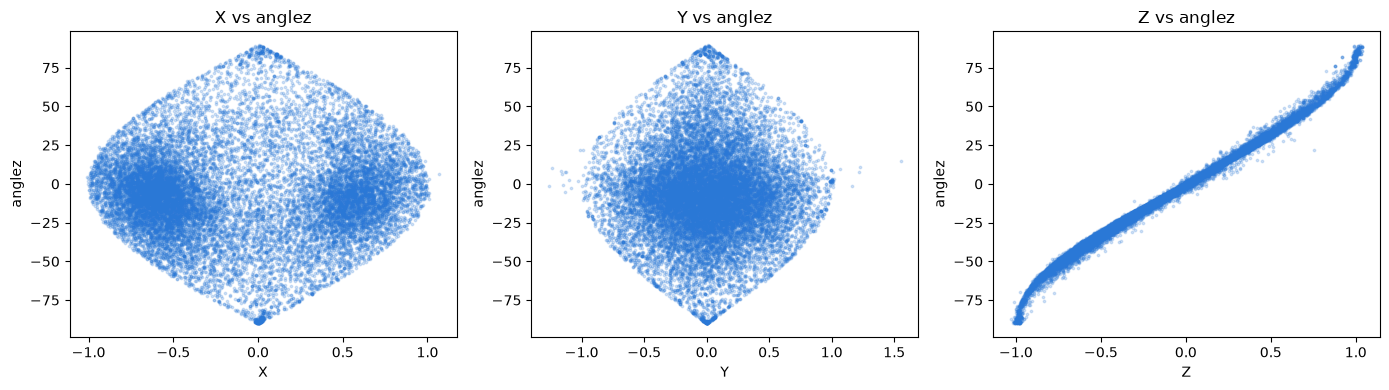

'\nRESULT: the \'Z vs anglez\' panel is a narrow, monotonic curve — literally the shape of an arctan function —\nconfirming a direct, near-deterministic functional relationship between the two. The \'X vs anglez\' and\n\'Y vs anglez\' panels instead form a wide, symmetric diamond-shaped cloud: for any fixed value of X (or Y),\nanglez can take almost any value in its full range. There is no usable functional relationship between X (or\nY) alone and anglez, which matches their near-zero correlation in the heatmap above.\n\nFINAL CONCLUSION\nThe initial hypothesis ("X and Y barely move, so anglez ends up reflecting only Z") pointed in the right\ndirection but for the wrong reason. The data show the opposite premise: X and Y do NOT move less than Z\n(their std is equal to or higher than Z\'s). The actual cause is structural/mathematical: anglez is DEFINED as\narctan(Z / sqrt(X^2 + Y^2)) * 180/pi. Z enters this formula on its own and directly controls the sign and\nmagnitude of the output, 

In [27]:
# STEP 4 — scatter anglez against each axis individually. Plotting all 887,400 rows would be extremely
# slow and mostly overplotted, so we draw a random sample of 20,000 rows (fixed seed for reproducibility)
# purely for visualization; the correlation numbers above were already computed on the FULL dataset.
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(df_all), size=20000, replace=False)
sample = df_all.iloc[sample_idx]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['X', 'Y', 'Z']):
    ax.scatter(sample[col], sample['anglez'], s=3, alpha=0.2, color='#2a78d6')
    ax.set_xlabel(col)
    ax.set_ylabel('anglez')
    ax.set_title(f'{col} vs anglez')
plt.tight_layout()
plt.show()

"""
RESULT: the 'Z vs anglez' panel is a narrow, monotonic curve — literally the shape of an arctan function —
confirming a direct, near-deterministic functional relationship between the two. The 'X vs anglez' and
'Y vs anglez' panels instead form a wide, symmetric diamond-shaped cloud: for any fixed value of X (or Y),
anglez can take almost any value in its full range. There is no usable functional relationship between X (or
Y) alone and anglez, which matches their near-zero correlation in the heatmap above.

FINAL CONCLUSION
The initial hypothesis ("X and Y barely move, so anglez ends up reflecting only Z") pointed in the right
direction but for the wrong reason. The data show the opposite premise: X and Y do NOT move less than Z
(their std is equal to or higher than Z's). The actual cause is structural/mathematical: anglez is DEFINED as
arctan(Z / sqrt(X^2 + Y^2)) * 180/pi. Z enters this formula on its own and directly controls the sign and
magnitude of the output, while X and Y are collapsed into a single non-negative magnitude term that discards
their individual directional information and has comparatively little influence on the output angle. That is
why Z and anglez correlate at 0.99 (near-perfect, because the derivation is almost a direct one-to-one
function of Z) while X and Y correlate at ~0 with anglez (because their individual values are not recoverable
from — and barely influence — the formula's output).

PRACTICAL IMPLICATION: keeping both Z and anglez as separate features in a linear model is close to redundant
(multicollinearity risk) since one is almost a deterministic transform of the other. X and Y, on the other
hand, are NOT redundant with enmo/anglez — they carry orientation/direction information that the derived
features discard — so they should not be dropped from the analysis just because they look 'uncorrelated' with
the summary features.
"""

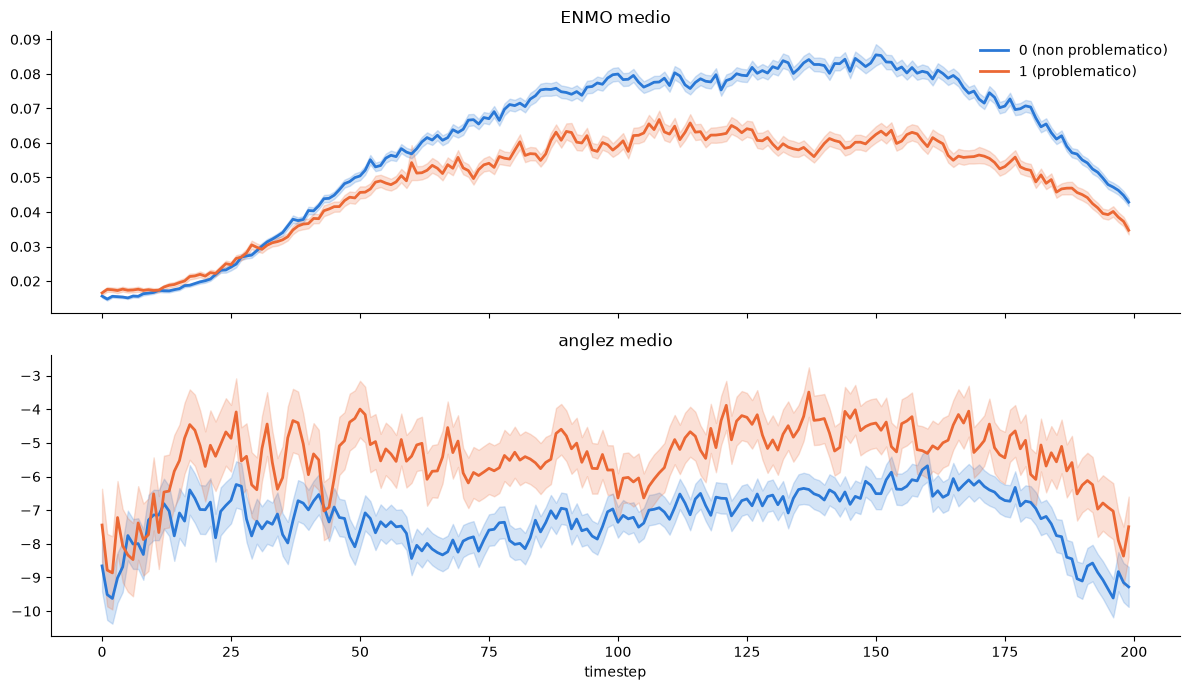

classe 0: enmo medio=0.0607  anglez medio=-7.25
classe 1: enmo medio=0.0489  anglez medio=-5.43


"\nse le due classi mostrano pattern medi diversi lungo la serie, enmo/anglez potrebbero essere feature discriminanti\nutili per la classificazione\n\nRISULTATO NUMERICO: la classe 1 (problematico) ha un enmo medio più basso (0.049) della classe 0 (0.061):\ni soggetti con sii problematico si muovono, in media, un po' meno lungo tutta la registrazione. La differenza\nè coerente lungo quasi tutto l'asse temporale (le due curve non si incrociano molto) ma è modesta in valore\nassoluto e le bande di errore standard (SEM) delle due classi si sovrappongono in diversi punti, quindi il segnale\nè reale ma debole: enmo da solo probabilmente non basta a separare bene le due classi, va combinato con altre feature.\nAnche anglez medio differisce leggermente fra le classi (-7.25 vs -5.43): un angolo del polso mediamente diverso\npuò riflettere una postura/abitudine di utilizzo del dispositivo leggermente diversa fra i due gruppi, ma anche\nqui la differenza è di pochi gradi, da trattare come indizi

In [28]:
# SERIE TEMPORALI MEDIE PER CLASSE (enmo e anglez)
enmo_matrix = np.array([d['enmo'].values for d in df_list])       # shape (4437, 200)
anglez_matrix = np.array([d['anglez'].values for d in df_list])
labels = np.array(sii_values)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for cls, color, name in zip([0, 1], ['#2a78d6', '#eb6834'], ['0 (non problematico)', '1 (problematico)']):
    mask = labels == cls
    for ax, matrix, title in zip(axes, [enmo_matrix, anglez_matrix], ['ENMO medio', 'anglez medio']):
        mean = matrix[mask].mean(axis=0)
        sem = matrix[mask].std(axis=0) / np.sqrt(mask.sum())
        t = np.arange(len(mean))
        ax.plot(t, mean, color=color, label=name, linewidth=2)
        ax.fill_between(t, mean - sem, mean + sem, color=color, alpha=0.2)
        ax.set_title(title)
        ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(frameon=False)
axes[1].set_xlabel('timestep')
plt.tight_layout()
plt.show()

for cls in [0, 1]:
    mask = labels == cls
    print(f"classe {cls}: enmo medio={enmo_matrix[mask].mean():.4f}  anglez medio={anglez_matrix[mask].mean():.2f}")

"""
se le due classi mostrano pattern medi diversi lungo la serie, enmo/anglez potrebbero essere feature discriminanti
utili per la classificazione

RISULTATO NUMERICO: la classe 1 (problematico) ha un enmo medio più basso (0.049) della classe 0 (0.061):
i soggetti con sii problematico si muovono, in media, un po' meno lungo tutta la registrazione. La differenza
è coerente lungo quasi tutto l'asse temporale (le due curve non si incrociano molto) ma è modesta in valore
assoluto e le bande di errore standard (SEM) delle due classi si sovrappongono in diversi punti, quindi il segnale
è reale ma debole: enmo da solo probabilmente non basta a separare bene le due classi, va combinato con altre feature.
Anche anglez medio differisce leggermente fra le classi (-7.25 vs -5.43): un angolo del polso mediamente diverso
può riflettere una postura/abitudine di utilizzo del dispositivo leggermente diversa fra i due gruppi, ma anche
qui la differenza è di pochi gradi, da trattare come indizio debole più che come feature fortemente separatrice.
"""

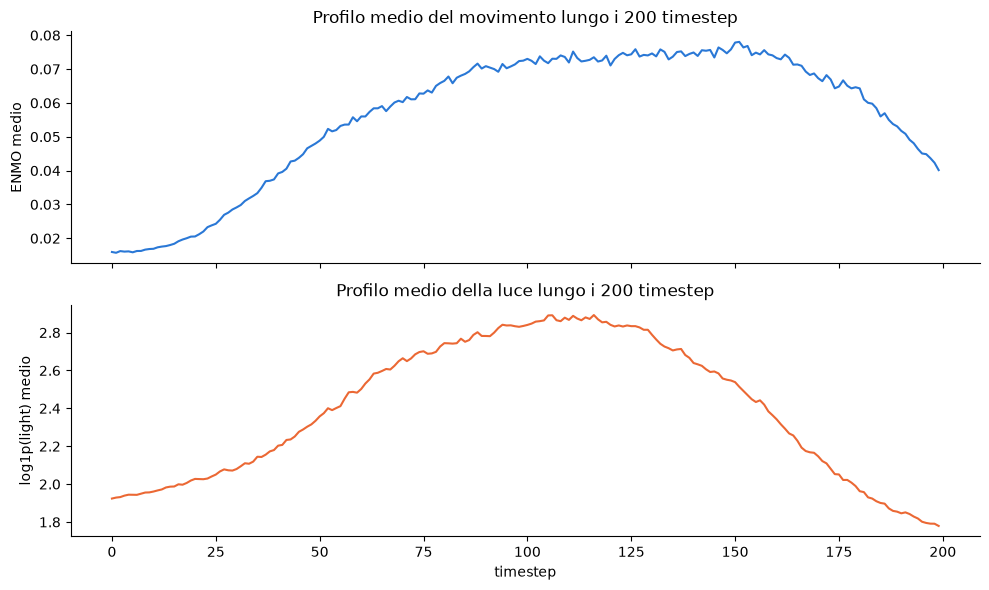

enmo: minimo allo step 1 (0.016), massimo allo step 151 (0.078)
log1p(light): minimo allo step 199, massimo allo step 116


'\nRISULTATO: le curve mostrano UNA sola gobba su tutta la finestra: bassa all\'inizio e alla fine, alta al centro.\nNon è ciò che ci si aspetterebbe da 100 ore contigue, che mostrerebbero 4 cicli giorno-notte. La prima versione di\nquesta cella ripiegava i dati con timestep % 48 assumendo un giorno = 48 step, e leggeva come "periodicità di 24 ore"\nil risultato di quel ripiegamento. L\'ipotesi è verificata in dettaglio in P4 (Data Preparation).\n'

In [29]:
# PROFILO MEDIO LUNGO LA FINESTRA: enmo e light per timestep, su tutte le finestre
enmo_step = enmo_matrix.mean(axis=0)
light_matrix = np.array([d['light'].values for d in df_list])
light_log_step = np.log1p(light_matrix.clip(0)).mean(axis=0)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(enmo_step, color='#2a78d6')
axes[0].set_ylabel('ENMO medio')
axes[0].set_title('Profilo medio del movimento lungo i 200 timestep')
axes[1].plot(light_log_step, color='#eb6834')
axes[1].set_ylabel('log1p(light) medio')
axes[1].set_title('Profilo medio della luce lungo i 200 timestep')
axes[1].set_xlabel('timestep')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f"enmo: minimo allo step {enmo_step.argmin()} ({enmo_step.min():.3f}), massimo allo step {enmo_step.argmax()} ({enmo_step.max():.3f})")
print(f"log1p(light): minimo allo step {light_log_step.argmin()}, massimo allo step {light_log_step.argmax()}")

"""
RISULTATO: le curve mostrano UNA sola gobba su tutta la finestra: bassa all'inizio e alla fine, alta al centro.
Non è ciò che ci si aspetterebbe da 100 ore contigue, che mostrerebbero 4 cicli giorno-notte. La prima versione di
questa cella ripiegava i dati con timestep % 48 assumendo un giorno = 48 step, e leggeva come "periodicità di 24 ore"
il risultato di quel ripiegamento. L'ipotesi è verificata in dettaglio in P4 (Data Preparation).
"""

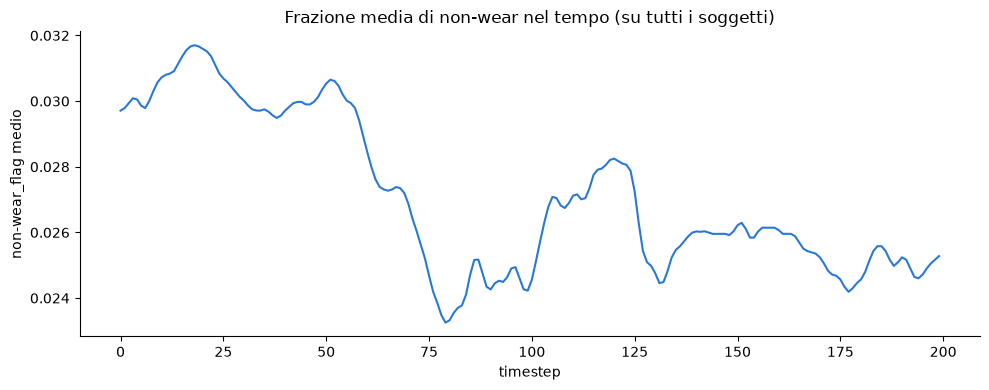

non-wear medio complessivo: 2.71%
min: 2.33%  max: 3.17%  (timestep 18)


'\nse il non-wear è concentrato solo in alcuni timestep (es. inizio/fine registrazione) possiamo gestirlo diversamente\nrispetto al caso in cui è distribuito uniformemente lungo la serie\n\nRISULTATO: la curva oscilla in un range molto stretto, circa 2.5%-3.2% lungo tutti i 200 timestep, senza un\npicco marcato né all\'inizio né alla fine della registrazione (che sarebbe stato il segnale tipico di "il\nsoggetto si toglie il dispositivo per dormire/farsi la doccia proprio a inizio/fine studio" o di un problema\ndi setup/rimozione del device durante l\'onboarding). Il livello medio complessivo è basso (~2.7%): la stragrande\nmaggioranza dei dati riflette quindi il sensore realmente indossato. Non essendoci una concentrazione strutturale\nin punti specifici della serie, non serve un trattamento speciale per timestep: il non-wear è più un rumore di\nfondo distribuito che un artefatto legato al protocollo di misura.\n'

In [30]:
# NON-WEAR_FLAG NEL TEMPO
nonwear_matrix = np.array([d['non-wear_flag'].values for d in df_list])
nonwear_per_timestep = nonwear_matrix.mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(len(nonwear_per_timestep)), nonwear_per_timestep, color='#2a78d6')
ax.set_xlabel('timestep')
ax.set_ylabel('non-wear_flag medio')
ax.set_title('Frazione media di non-wear nel tempo (su tutti i soggetti)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f"non-wear medio complessivo: {nonwear_per_timestep.mean()*100:.2f}%")
print(f"min: {nonwear_per_timestep.min()*100:.2f}%  max: {nonwear_per_timestep.max()*100:.2f}%  (timestep {nonwear_per_timestep.argmax()})")

"""
se il non-wear è concentrato solo in alcuni timestep (es. inizio/fine registrazione) possiamo gestirlo diversamente
rispetto al caso in cui è distribuito uniformemente lungo la serie

RISULTATO: la curva oscilla in un range molto stretto, circa 2.5%-3.2% lungo tutti i 200 timestep, senza un
picco marcato né all'inizio né alla fine della registrazione (che sarebbe stato il segnale tipico di "il
soggetto si toglie il dispositivo per dormire/farsi la doccia proprio a inizio/fine studio" o di un problema
di setup/rimozione del device durante l'onboarding). Il livello medio complessivo è basso (~2.7%): la stragrande
maggioranza dei dati riflette quindi il sensore realmente indossato. Non essendoci una concentrazione strutturale
in punti specifici della serie, non serve un trattamento speciale per timestep: il non-wear è più un rumore di
fondo distribuito che un artefatto legato al protocollo di misura.
"""

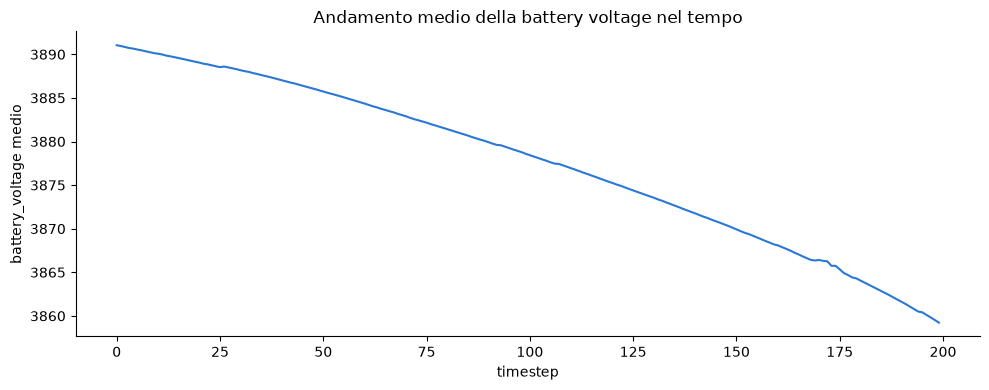

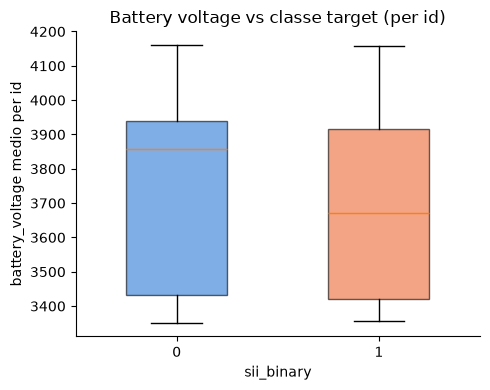

delta battery primo-ultimo timestep: -31.8 mV
battery media per id: classe 0 = 3739.7 mV, classe 1 = 3687.1 mV
t-test per finestra (sbagliato, osservazioni non indipendenti): p = 0.282
t-test per id (corretto):                                     p = 0.031


In [31]:
# BATTERY VOLTAGE - trend nel tempo e possibile confondente
battery_matrix = np.array([d['battery_voltage'].values for d in df_list])
battery_mean_per_timestep = battery_matrix.mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(battery_matrix.shape[1]), battery_mean_per_timestep, color='#2a78d6')
ax.set_xlabel('timestep')
ax.set_ylabel('battery_voltage medio')
ax.set_title('Andamento medio della battery voltage nel tempo')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# confronto fra classi fatto PER ID: le finestre dello stesso soggetto non sono osservazioni indipendenti,
# quindi prima si fa la media per id e poi il test sui 494 soggetti
battery_by_id = (pd.DataFrame({'id': ids_eda, 'y': labels, 'b': battery_matrix.mean(axis=1)})
                 .groupby('id').agg(b=('b', 'mean'), y=('y', 'first')))

fig, ax = plt.subplots(figsize=(5, 4))
bp = ax.boxplot([battery_by_id.b[battery_by_id.y == 0], battery_by_id.b[battery_by_id.y == 1]],
                tick_labels=['0', '1'], patch_artist=True, widths=0.5)
for patch, color in zip(bp['boxes'], ['#2a78d6', '#eb6834']):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.set_xlabel('sii_binary')
ax.set_ylabel('battery_voltage medio per id')
ax.set_title('Battery voltage vs classe target (per id)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

t_win = stats.ttest_ind(battery_matrix.mean(axis=1)[labels == 0], battery_matrix.mean(axis=1)[labels == 1])
t_id = stats.ttest_ind(battery_by_id.b[battery_by_id.y == 0], battery_by_id.b[battery_by_id.y == 1])
print(f"delta battery primo-ultimo timestep: {battery_mean_per_timestep[-1] - battery_mean_per_timestep[0]:.1f} mV")
print(f"battery media per id: classe 0 = {battery_by_id.b[battery_by_id.y == 0].mean():.1f} mV, classe 1 = {battery_by_id.b[battery_by_id.y == 1].mean():.1f} mV")
print(f"t-test per finestra (sbagliato, osservazioni non indipendenti): p = {t_win.pvalue:.3f}")
print(f"t-test per id (corretto):                                     p = {t_id.pvalue:.3f}")

**Risultato:** il primo grafico mostra un calo regolare di ~32 mV lungo la finestra: è la batteria che si scarica, un artefatto strumentale legato al tempo, non un segnale biologico.

Sul confronto fra le classi, il test va fatto **per id**: le finestre dello stesso soggetto non sono indipendenti e un id con 36 finestre peserebbe 36 volte. Fatto per finestra il test dice "nessuna differenza" (p≈0.28); fatto per id la differenza diventa significativa (p≈0.03). Non perché la batteria dipenda dal comportamento, ma perché gli id con una sola finestra hanno batteria molto più bassa e sono più spesso in classe 1 (vedi Data Preparation, P2 e P3). battery_voltage è quindi un potenziale **confondente** legato al tipo di registrazione: non va usato come input dei modelli. I 4 valori anomali (fino a 6000 mV, id 3539) vanno comunque corretti.

## ANDAMENTO DI TUTTE LE VARIABILI DYNAMIC

le variabili DYNAMIC sono quelle che cambiano ad ogni timestep all'interno della stessa time series
(X, Y, Z, enmo, anglez, non-wear_flag, light, battery_voltage), a differenza delle variabili STATIC
già individuate sopra (weekday, quarter, relative_date_PCIAT, id, sii_binary) che sono costanti dentro
ogni finestra. Qui generalizziamo a tutte le 8 variabili dynamic quello che finora avevamo fatto solo per
qualche colonna alla volta (X/Y/Z, enmo/light, non-wear_flag, battery_voltage).

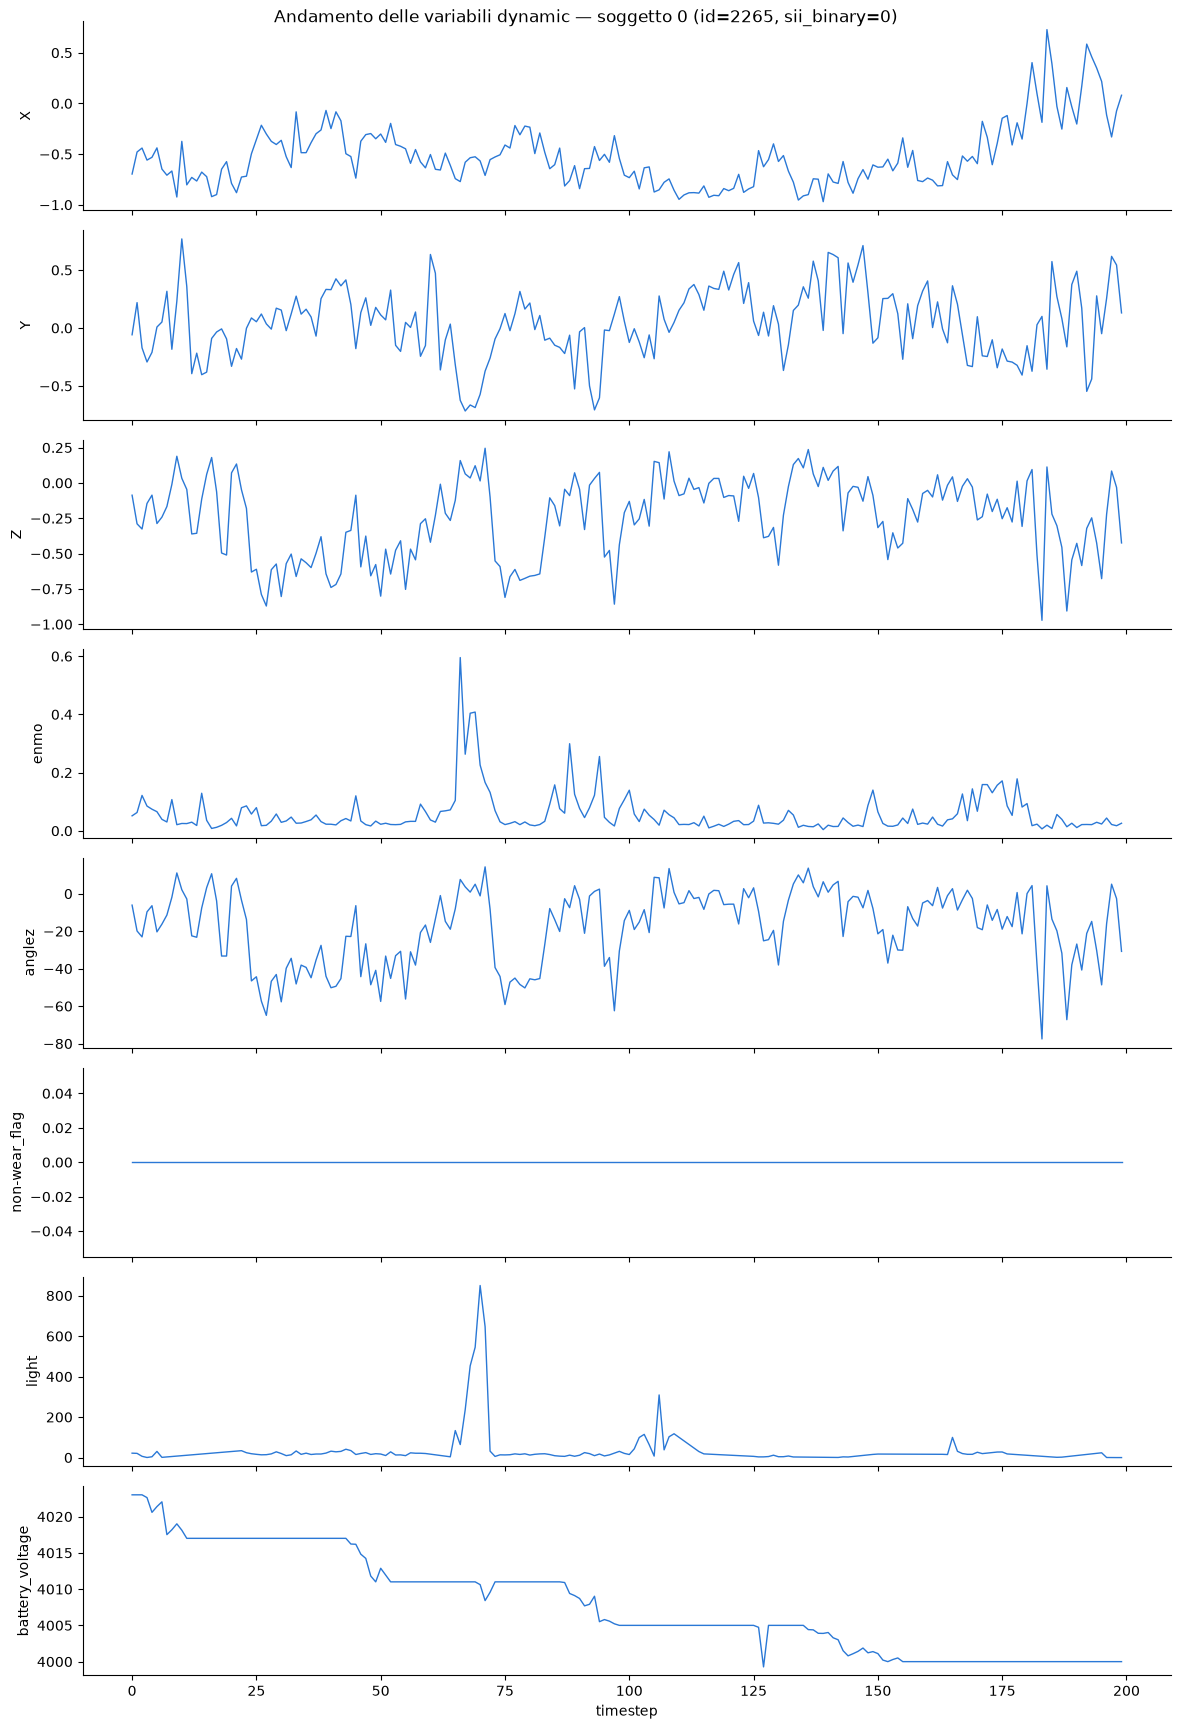

'\nvista d\'insieme utile come primo check qualitativo su un soggetto: si nota subito l\'andamento\ncondiviso da più variabili (enmo/light/anglez si muovono "insieme" nei momenti di attività), e permette di\nindividuare a colpo d\'occhio eventuali anomalie locali (es. un picco isolato su X/Z come quello trovato\nnell\'audit sopra) guardando tutte le variabili allineate sullo stesso asse temporale invece che una alla volta.\n'

In [32]:
DYNAMIC_COLS = ['X', 'Y', 'Z', 'enmo', 'anglez', 'non-wear_flag', 'light', 'battery_voltage']

# 1) SINGOLO SOGGETTO: griglia con l'andamento nel tempo di tutte le variabili dynamic per un soggetto a scelta

def plot_subject_dynamics(subject_idx, df_list=df_list, cols=DYNAMIC_COLS):
    d = df_list[subject_idx]
    n = len(cols)
    fig, axes = plt.subplots(n, 1, figsize=(12, 2.2 * n), sharex=True)
    for ax, col in zip(axes, cols):
        ax.plot(d.index, d[col].values, color='#2a78d6', linewidth=1)
        ax.set_ylabel(col)
        ax.spines[['top', 'right']].set_visible(False)
    axes[-1].set_xlabel('timestep')
    fig.suptitle(f"Andamento delle variabili dynamic — soggetto {subject_idx} (id={d['id'].iloc[0]}, sii_binary={d['sii_binary'].iloc[0]})")
    plt.tight_layout()
    plt.show()

plot_subject_dynamics(0)

"""
vista d'insieme utile come primo check qualitativo su un soggetto: si nota subito l'andamento
condiviso da più variabili (enmo/light/anglez si muovono "insieme" nei momenti di attività), e permette di
individuare a colpo d'occhio eventuali anomalie locali (es. un picco isolato su X/Z come quello trovato
nell'audit sopra) guardando tutte le variabili allineate sullo stesso asse temporale invece che una alla volta.
"""

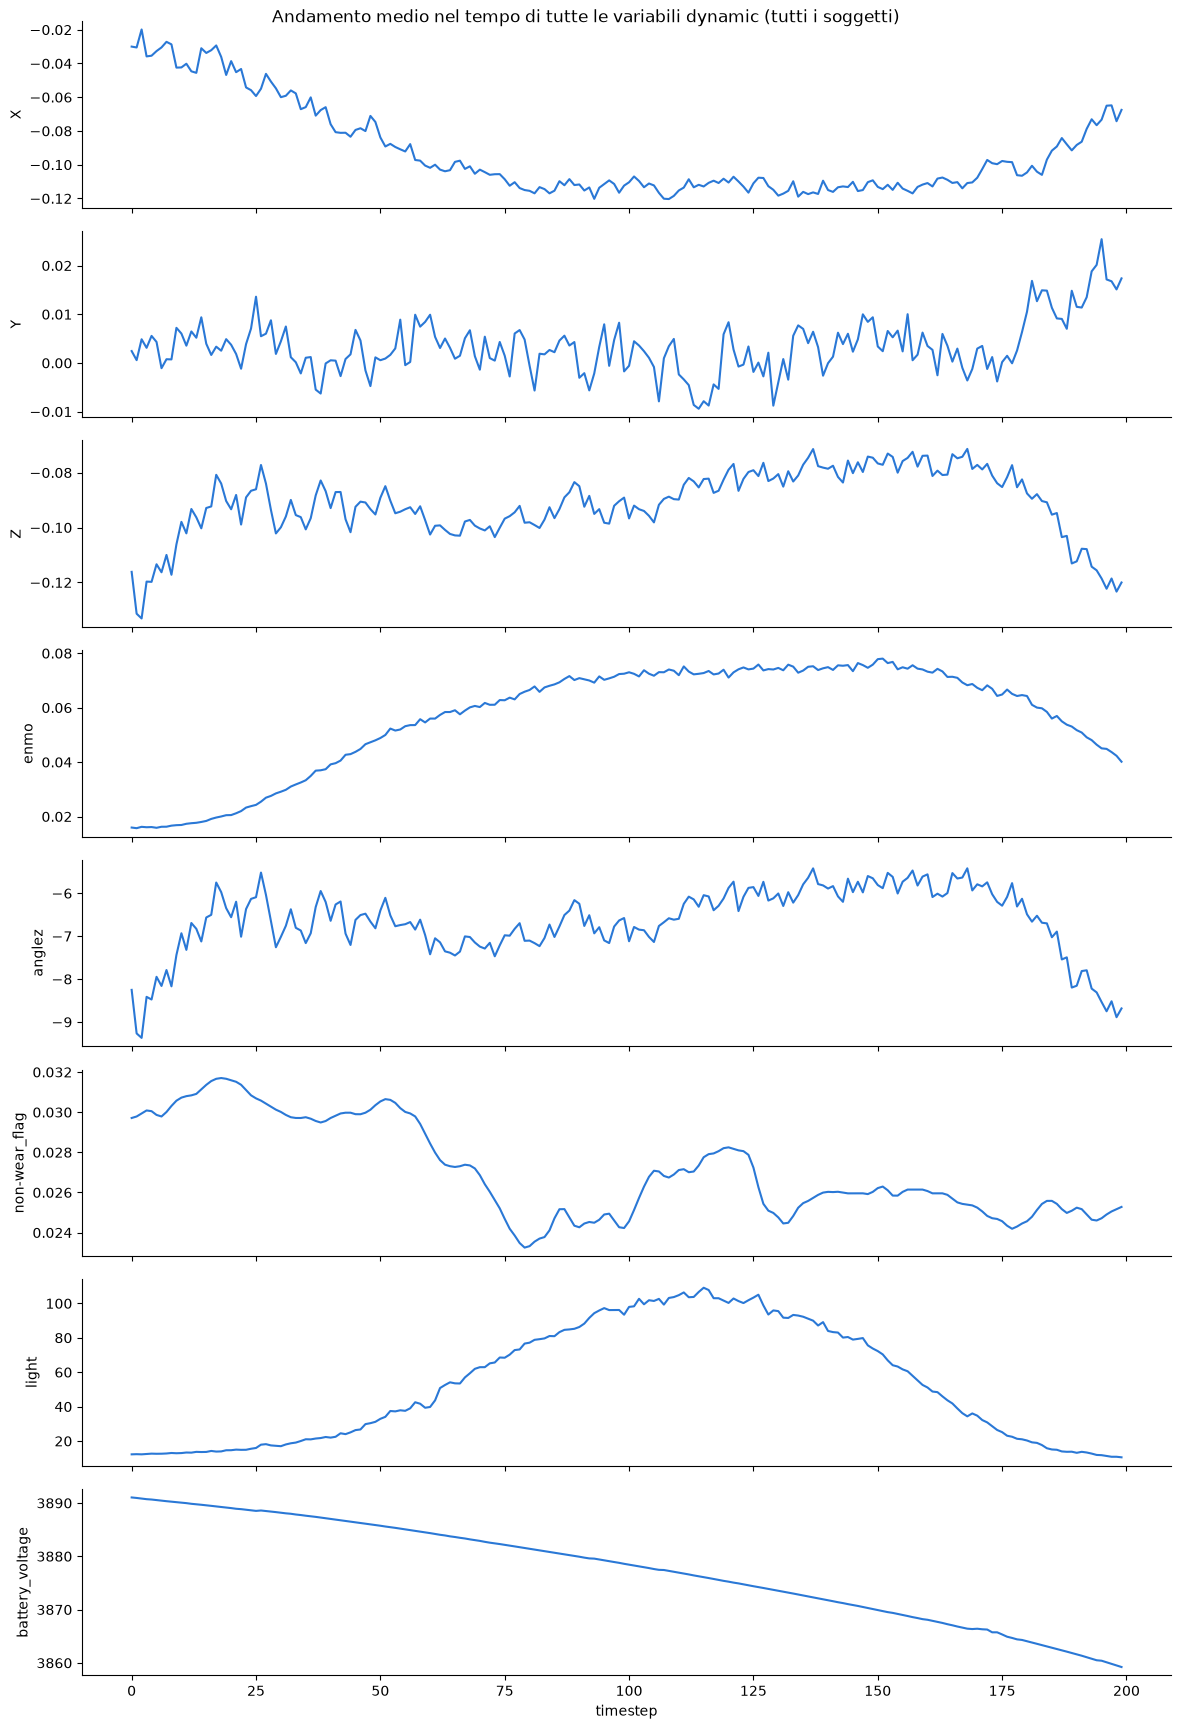

'\nmediando su tutti i soggetti il rumore individuale si cancella e restano solo i pattern sistematici: qui si\nvede bene il ciclo unico di enmo/light/anglez già discusso sopra, il trend discendente e regolare\ndi battery_voltage (scarica della batteria nel tempo), e il livello sostanzialmente piatto di non-wear_flag.\nX e Y oscillano molto meno di Z/anglez/light a livello di media aggregata (Y è quasi piatto, X mostra solo una\npiccola oscillazione residua): essendo assi "di direzione" il loro segno dipende da come il dispositivo è\nindossato da ciascun soggetto, quindi mediare fra soggetti tende ad annullare parte del pattern che invece è\nben visibile nel singolo soggetto (cella precedente) — un promemoria importante: la media aggregata è utile\nper i pattern comuni a tutti, ma può "nascondere" segnali che esistono a livello individuale ma con fase/segno\ndiversi fra soggetti.\n'

In [33]:
# 2) MEDIA AGGREGATA NEL TEMPO: una curva per variabile, media su tutte le 4437 finestre (nessuna distinzione di classe)

def build_dynamic_matrices(df_list=df_list, cols=DYNAMIC_COLS):
    """restituisce un dict {colonna: matrice (n_soggetti, n_timestep)}"""
    return {col: np.array([d[col].values for d in df_list]) for col in cols}

dynamic_matrices = build_dynamic_matrices()

fig, axes = plt.subplots(len(DYNAMIC_COLS), 1, figsize=(12, 2.2 * len(DYNAMIC_COLS)), sharex=True)
for ax, col in zip(axes, DYNAMIC_COLS):
    mean_per_timestep = dynamic_matrices[col].mean(axis=0)
    ax.plot(np.arange(len(mean_per_timestep)), mean_per_timestep, color='#2a78d6', linewidth=1.5)
    ax.set_ylabel(col)
    ax.spines[['top', 'right']].set_visible(False)
axes[-1].set_xlabel('timestep')
fig.suptitle('Andamento medio nel tempo di tutte le variabili dynamic (tutti i soggetti)')
plt.tight_layout()
plt.show()

"""
mediando su tutti i soggetti il rumore individuale si cancella e restano solo i pattern sistematici: qui si
vede bene il ciclo unico di enmo/light/anglez già discusso sopra, il trend discendente e regolare
di battery_voltage (scarica della batteria nel tempo), e il livello sostanzialmente piatto di non-wear_flag.
X e Y oscillano molto meno di Z/anglez/light a livello di media aggregata (Y è quasi piatto, X mostra solo una
piccola oscillazione residua): essendo assi "di direzione" il loro segno dipende da come il dispositivo è
indossato da ciascun soggetto, quindi mediare fra soggetti tende ad annullare parte del pattern che invece è
ben visibile nel singolo soggetto (cella precedente) — un promemoria importante: la media aggregata è utile
per i pattern comuni a tutti, ma può "nascondere" segnali che esistono a livello individuale ma con fase/segno
diversi fra soggetti.
"""

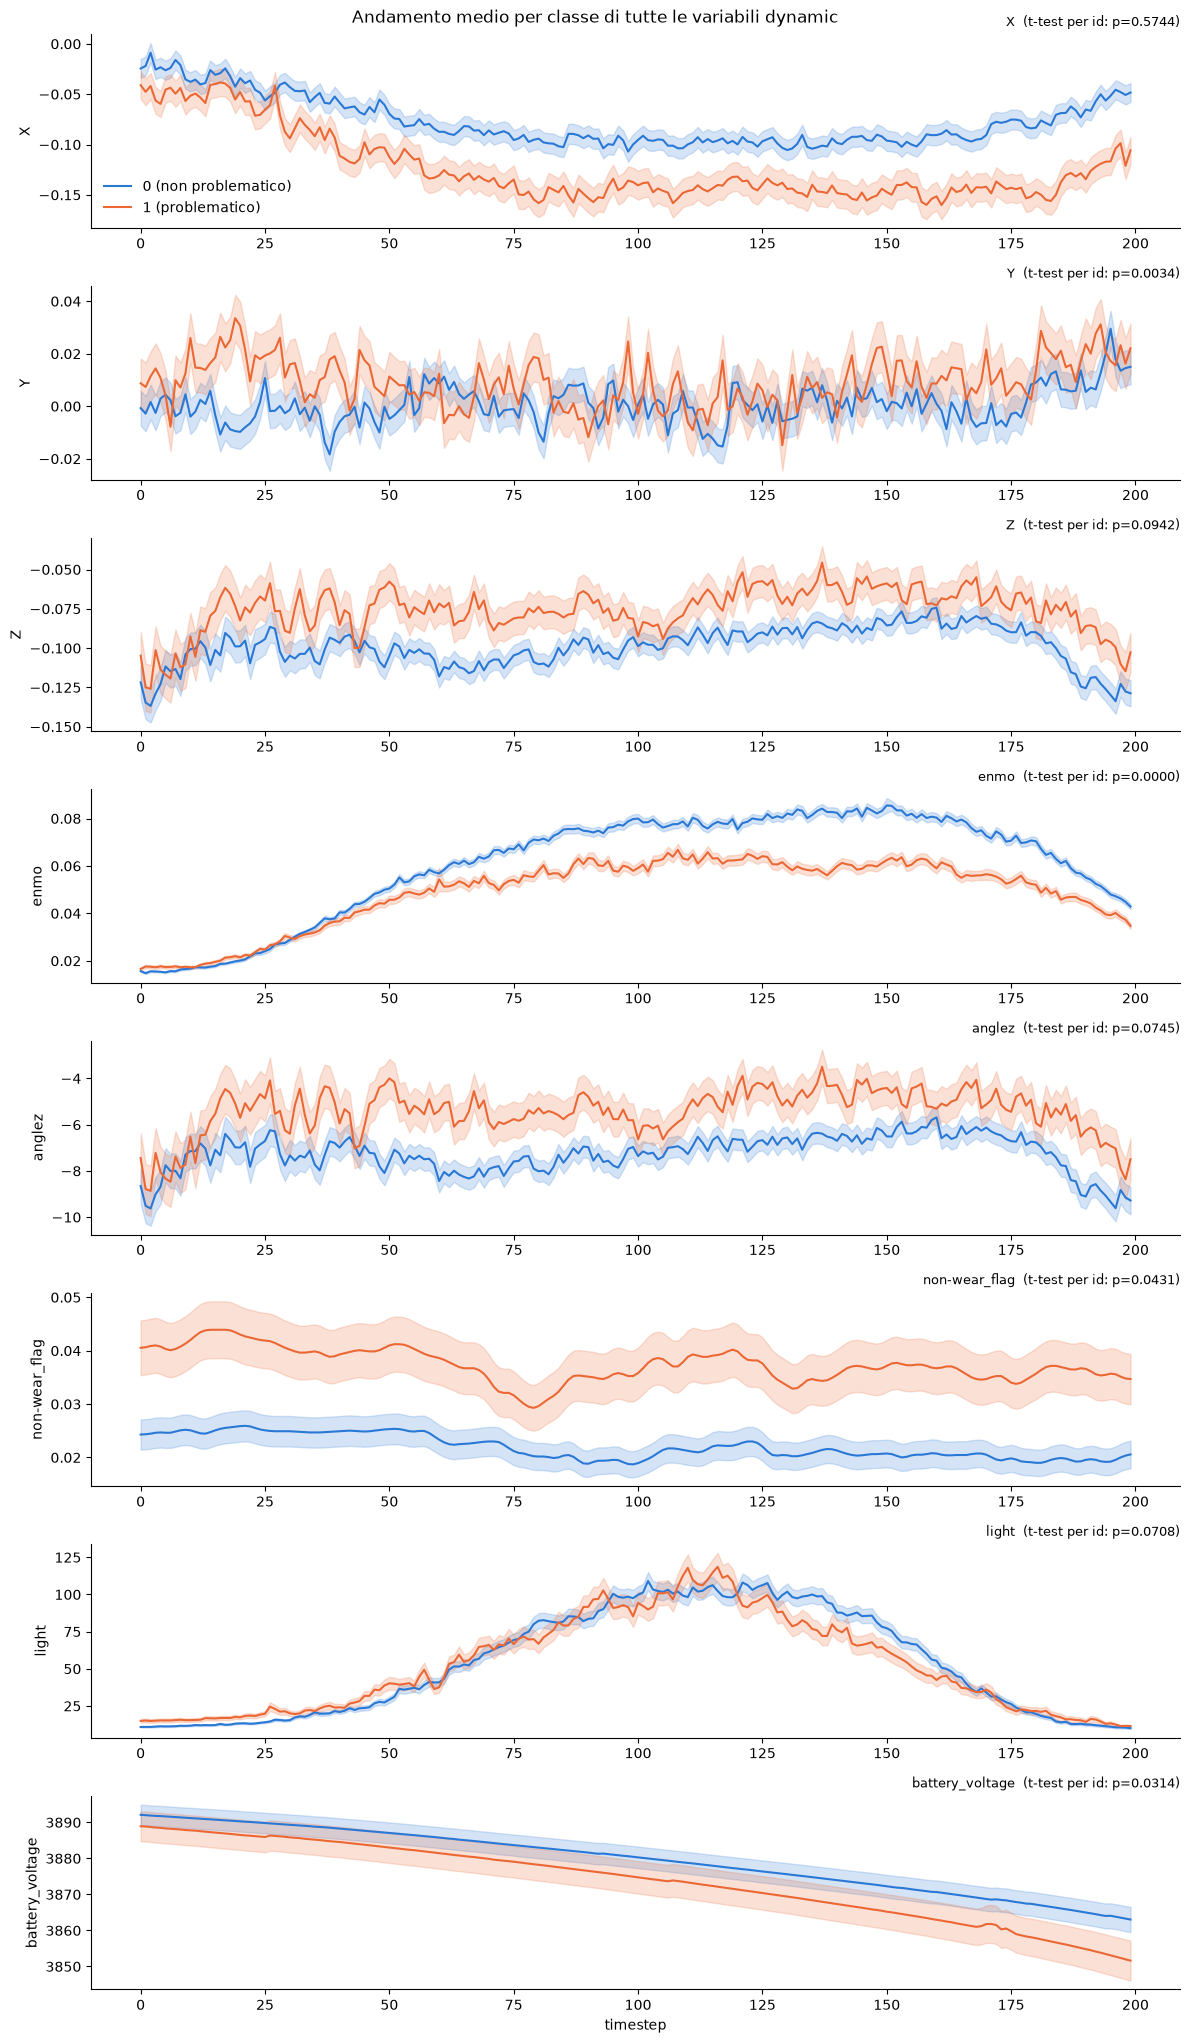

                 p per finestra (non valido)  p per id
enmo                            4.595938e-47  0.000044
Y                               3.856525e-02  0.003425
battery_voltage                 2.823012e-01  0.031438
non-wear_flag                   7.410763e-04  0.043066
light                           5.802949e-01  0.070819
anglez                          6.369236e-04  0.074499
Z                               1.453559e-03  0.094248
X                               1.748608e-04  0.574390


In [34]:
# 3) MEDIA AGGREGATA PER CLASSE: due curve per variabile (sii_binary 0 vs 1) con banda di errore standard (SEM),
# generalizzando a tutte le variabili dynamic quanto fatto sopra solo per enmo/anglez

fig, axes = plt.subplots(len(DYNAMIC_COLS), 1, figsize=(12, 2.6 * len(DYNAMIC_COLS)), sharex=False)

pvalues_window, pvalues_id = {}, {}
for ax, col in zip(axes, DYNAMIC_COLS):
    matrix = dynamic_matrices[col]
    for cls, color, name in zip([0, 1], ['#2a78d6', '#eb6834'], ['0 (non problematico)', '1 (problematico)']):
        mask = labels == cls
        mean = matrix[mask].mean(axis=0)
        sem = matrix[mask].std(axis=0) / np.sqrt(mask.sum())
        t = np.arange(len(mean))
        ax.plot(t, mean, color=color, label=name, linewidth=1.5)
        ax.fill_between(t, mean - sem, mean + sem, color=color, alpha=0.2)
    ax.set_ylabel(col)
    ax.spines[['top', 'right']].set_visible(False)

    # test sulla media PER ID (il test per finestra è tenuto solo per confronto)
    win_mean = matrix.mean(axis=1)
    by_id = pd.DataFrame({'id': ids_eda, 'y': labels, 'v': win_mean}).groupby('id').agg(v=('v', 'mean'), y=('y', 'first'))
    pvalues_window[col] = stats.ttest_ind(win_mean[labels == 0], win_mean[labels == 1]).pvalue
    pvalues_id[col] = stats.ttest_ind(by_id.v[by_id.y == 0], by_id.v[by_id.y == 1]).pvalue
    ax.set_title(f"{col}  (t-test per id: p={pvalues_id[col]:.4f})", fontsize=9, loc='right')

axes[0].legend(frameon=False)
axes[-1].set_xlabel('timestep')
fig.suptitle('Andamento medio per classe di tutte le variabili dynamic')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'p per finestra (non valido)': pvalues_window, 'p per id': pvalues_id}).sort_values('p per id'))

**Risultato:** rifacendo i test per id (494 soggetti indipendenti invece di 4437 finestre correlate) i p-value cambiano molto, e alcune conclusioni precedenti non reggono:

- **enmo** resta l'unica differenza netta (p≈4e-5): la classe problematica si muove meno. È il segnale su cui puntare.
- **Y** e **non-wear_flag** restano sotto 0.05, ma la differenza su non-wear è guidata dagli id con una sola finestra, che hanno molto più non-wear (vedi Data Preparation, P2). Più che un comportamento, segnala un tipo di registrazione diverso: rischio di "scorciatoia" per i modelli.
- **X, Z, anglez** erano significativi per finestra ma **non** lo sono per id: l'effetto era un artefatto della pseudo-replicazione (gli id con molte finestre contano molte volte).
- **battery_voltage** diventa significativo per id (p≈0.03): confondente strumentale, non segnale (cella sopra).
- **light** non è significativo in nessuno dei due casi.

Lezione metodologica: in questo dataset qualunque statistica che confronta le classi va calcolata per id.

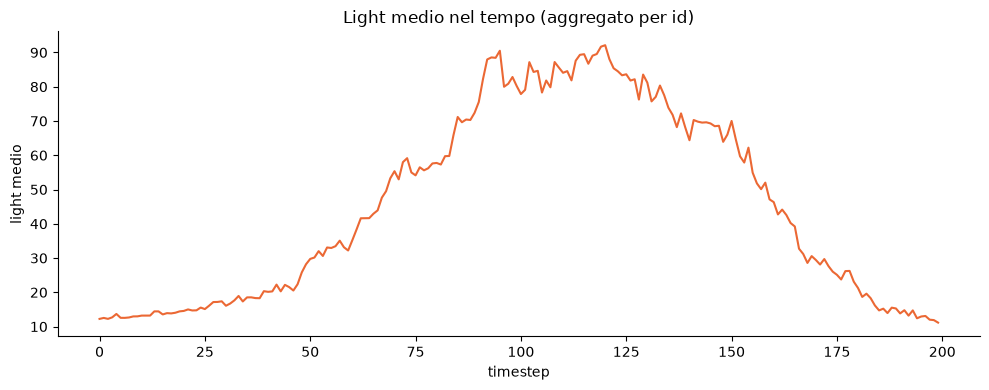

In [35]:
ids = np.array([d['id'].iloc[0] for d in df_list])
light_matrix = np.array([d['light'].values for d in df_list])   # shape (n_finestre, 200)

# prima aggreghiamo per id: una serie di 200 timestep per ogni soggetto unico
# (media fra le finestre dello stesso id), così un id con 36 finestre non pesa
# 36 volte di più di un id con una sola finestra
light_by_id = pd.DataFrame(light_matrix, index=ids).groupby(level=0).mean()  # shape (n_id_unici, 200)

# poi calcoliamo la media fra soggetti, timestep per timestep
light_mean = light_by_id.mean(axis=0).values

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(light_mean, color='#eb6834')
ax.set_xlabel('timestep')
ax.set_ylabel('light medio')
ax.set_title('Light medio nel tempo (aggregato per id)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()